In [1]:
# IMPORTS -------------------------------------------------------------------- #
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import pandas as pd
import seaborn as sns

import utils

workspace,experiment=utils.workspace()
from __future__ import annotations

sys.path = [p for p in sys.path if "positron-python" not in p]

import anndata as ad
import scanpy as sc

# Settings

| Package    | Version |
| ---------- | ------- |
| matplotlib | 3.11.1  |
| numpy      | 2.4.6   |
| anndata    | 0.13.2  |
| scanpy     | 1.12.3  |

| Dependency        | Version         |
| ----------------- | --------------- |
| cycler            | 0.12.1          |
| parso             | 0.8.7           |
| ipython           | 9.16.1 (8.18.1) |
| session-info2     | 0.4.2           |
| scikit-learn      | 1.9.0           |
| pexpect           | 4.9.0           |
| jupyter_client    | 8.9.1 (8.6.3)   |
| PyYAML            | 6.0.3           |
| ptyprocess        | 0.7.0           |
| wcwidth           | 0.8.2 (0.8.1)   |
| jedi              | 0.20.0 (0.19.2) |
| numba             | 0.66.0          |
| pure_eval         | 0.2.3           |
| debugpy           | 1.8.21          |
| pyzmq             | 27.1.0          |
| stack_data        | 0.6.3           |
| psutil            | 7.2.2           |
| donfig            | 0.8.1.post1     |
| prompt_toolkit    | 3.0.53 (3.0.52) |
| python-dateutil   | 2.9.0.post0     |
| ipykernel         | 7.3.0 (6.31.0)  |
| threadpoolctl     | 3.6.0           |
| pillow            | 12.3.0          |
| pyparsing         | 3.3.2           |
| pydantic          | 2.13.4          |
| kiwisolver        | 1.5.0           |
| python-dotenv     | 1.2.2           |
| natsort           | 8.4.0           |
| jupyter_core      | 5.9.1 (5.8.1)   |
| setuptools        | 83.0.0          |
| Pygments          | 2.20.0          |
| fast-array-utils  | 1.5             |
| fonttools         | 4.63.0          |
| numcodecs         | 0.16.5          |
| pydantic_core     | 2.46.4          |
| platformdirs      | 4.11.0 (4.4.0)  |
| six               | 1.17.0          |
| packaging         | 26.2            |
| scipy             | 1.18.0          |
| pydantic-settings | 2.14.2          |
| h5py              | 3.16.0          |
| executing         | 2.2.1           |
| asttokens         | 3.0.2           |
| typing-inspection | 0.4.2           |
| comm              | 0.2.3           |
| zarr              | 3.3.0           |
| traitlets         | 5.16.1 (5.15.1) |
| joblib            | 1.5.3           |
| pandas            | 3.0.5           |
| msgpack           | 1.2.1           |
| legacy-api-wrap   | 1.5             |
| llvmlite          | 0.48.0          |
| annotated-types   | 0.8.0           |
| narwhals          | 2.24.0          |
| google-crc32c     | 1.8.0           |
| scverse-misc      | 0.1.3           |
| typing_extensions | 4.16.0          |
| tornado           | 6.5.7           |

| Component | Info                                                                          |
| --------- | ----------------------------------------------------------------------------- |
| Python    | 3.14.6 | packaged by conda-forge | (main, Jul 24 2026, 16:09:24) [GCC 14.3.0] |
| OS        | Linux-6.1.0-48-amd64-x86_64-with-glibc2.36                                    |
| CPU       | 256/256 logical CPU cores                                                     |
| GPU       | No GPU found                                                                  |
| Updated   | 2026-08-10 08:24                                                              |

In [2]:
# SETTINGS ------------------------------------------------------------------- #
# verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.verbosity = 3
# Set figure parameters for clean, minimal plots
sc.set_figure_params(dpi=80,facecolor='white', frameon=False)

# Read Data

In [3]:
# PATHS ---------------------------------------------------------------------- #
results_file = workspace/'data/pbmc3k.h5ad'
read_file=workspace/'data/practice_adata/filtered_gene_bc_matrices/hg19'

In [4]:
# READ 10X-GENOMICS-FORMATTED MTX DIRECTORY ---------------------------------- #
# path: Path to directory for .mtx and .tsv files
# var_names: the variables index (options from genes.tsv file: 'gene_symbols', 'gene_ids')
# make_unique: Whether to make the variables index unique by appending ‘-1’, ‘-2’ etc. or not.
# cache: If False, read from source, if True, read from fast ‘h5ad’ cache.
# ---------------------------------------------------------------------------- #
genes=pd.read_csv(read_file/'genes.tsv',sep='\t',header=None).rename(columns={0:'gene_ids',1:'gene_symbols'})
adata = sc.read_10x_mtx(
    path=read_file,
    var_names='gene_symbols', #  # use gene symbols for the variable names (variables-axis index)
    make_unique=True, # make gene symbols unique
    cache=True, # write a cache file for faster subsequent reading
    )
adata.write(workspace/'data/practice_adata/pbmc3k_raw.h5ad')
adata

... reading from cache file cache/omics-odcf-analysis-OE0290_projects-heroes-aya_pools-AG_Thongjuea-Code-10x_multiomics-Selina-project-data-practice_adata-filtered_gene_bc_matrices-hg19-matrix.h5ad


AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [5]:
# DUPLICATE GENE SYMBOLS ----------------------------------------------------- #
# during read_10x_mtx, some gene_symbols are already recognized as duplicates
# they receive an appendage: U1 -> [U1, U1-1]
# ---------------------------------------------------------------------------- #

print(adata.var.index.duplicated().sum()) # if 0 no adata.var_names_make_unique() necessary

dupl = [idx.replace('-1','') for idx in adata.var.index if idx.endswith('-1') and idx.replace('-1','') in adata.var.index]
genes_duplicated = genes[genes.gene_symbols.duplicated()].drop_duplicates(subset=['gene_symbols'])
genes_duplicated.shape, len(dupl)

pd_dupl = pd.DataFrame([{'symbol':gene,'genes':genes.query('gene_symbols==@gene').shape[0],'adata':adata.var.reset_index(names='gene_symbols').query('gene_symbols==@gene').shape[0]} for gene in dupl])
pd_dupl.head(5)

0


,symbol,genes,adata
0,U1,2,1
1,EFNA3,2,1
2,DCAF8,2,1
3,MRPL30,2,1
4,LIMS3,2,1


# Quality Control

## Basic filtering

In [6]:
# FILTER --------------------------------------------------------------------- #
sc.pp.filter_cells(adata, min_genes=200) 
sc.pp.filter_genes(adata, min_cells=3) 

filtered out 19024 genes that are detected in less than 3 cells


## Calculate metrics

In [7]:
# DEFINE GENES --------------------------------------------------------------- #
# mitochondrial genes
genes_mt = adata.var_names.str.startswith("MT-")
adata.var["mt"] = genes_mt
# ribosomal genes
genes_ribo = adata.var_names.str.startswith(("RPCS","RPL"))
adata.var["ribo"] = genes_ribo
# hemoglobin genes.
genes_hb = adata.var_names.str.contains(r"^HB[ABDEGMQZ]\d*(?!\w)")
adata.var["hb"] = genes_hb
sum(genes_mt),sum(genes_ribo),sum(genes_hb)

(np.int64(13), np.int64(52), np.int64(2))

In [8]:
# CALCULATE QUALITY CONTROL METRICS ------------------------------------------ #
# qc_vars: Keys for boolean columns of .var which identify variables you could want to control for 
# percent_top: List of ranks (where genes are ranked by expression) at which the cumulative proportion of expression will be reported as a percentage. (default: (50, 100, 200, 500))
# log1p: Set to False to skip computing log1p transformed annotations.
# ---------------------------------------------------------------------------- #

sc.pp.calculate_qc_metrics(
    adata, 
    qc_vars=["mt", "ribo", "hb"], 
    inplace=True, 
    percent_top=[20], 
    # percent_top=None, 
    log1p=True
)
print(adata)
list(adata.obs.columns)

AnnData object with n_obs × n_vars = 2700 × 13714
    obs: 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'gene_ids', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)


['n_genes',
 'n_genes_by_counts',
 'log1p_n_genes_by_counts',
 'total_counts',
 'log1p_total_counts',
 'pct_counts_in_top_20_genes',
 'total_counts_mt',
 'log1p_total_counts_mt',
 'pct_counts_mt',
 'total_counts_ribo',
 'log1p_total_counts_ribo',
 'pct_counts_ribo',
 'total_counts_hb',
 'log1p_total_counts_hb',
 'pct_counts_hb']

In [9]:
# OBS ------------------------------------------------------------------------ #
adata.obs.describe()

,n_genes,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_20_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,total_counts_ribo,log1p_total_counts_ribo,pct_counts_ribo,total_counts_hb,log1p_total_counts_hb,pct_counts_hb
count,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000
mean,846.994074,845.546667,6.689682,2365.376953,7.677885,27.570190,50.806667,3.790158,2.216642,481.811096,6.047640,20.568111,0.032593,0.011250,0.001761
std,282.104964,281.347923,0.323935,1093.378784,0.431357,3.337459,30.891550,0.582522,1.166708,233.939194,0.566935,5.803408,0.610860,0.130827,0.031942
min,212.000000,212.000000,5.361292,546.000000,6.304449,17.087902,0.000000,0.000000,0.000000,6.000000,1.945910,0.636943,0.000000,0.000000,0.000000
25%,690.000000,690.000000,6.538140,1755.750000,7.471221,25.437124,31.000000,3.465736,1.537264,317.000000,5.762052,15.900984,0.000000,0.000000,0.000000
50%,817.000000,816.000000,6.705639,2196.000000,7.694848,27.268371,44.000000,3.806663,2.030800,461.000000,6.135565,21.496486,0.000000,0.000000,0.000000
75%,953.250000,952.000000,6.859615,2762.250000,7.924163,29.302849,62.000000,4.143135,2.643177,609.000000,6.413459,25.283747,0.000000,0.000000,0.000000
max,3422.000000,3400.000000,8.131825,15818.000000,9.668967,54.434783,347.000000,5.852202,22.569027,2450.000000,7.804251,35.666664,27.000000,3.332205,1.363636


## Outliers

### metrics plots

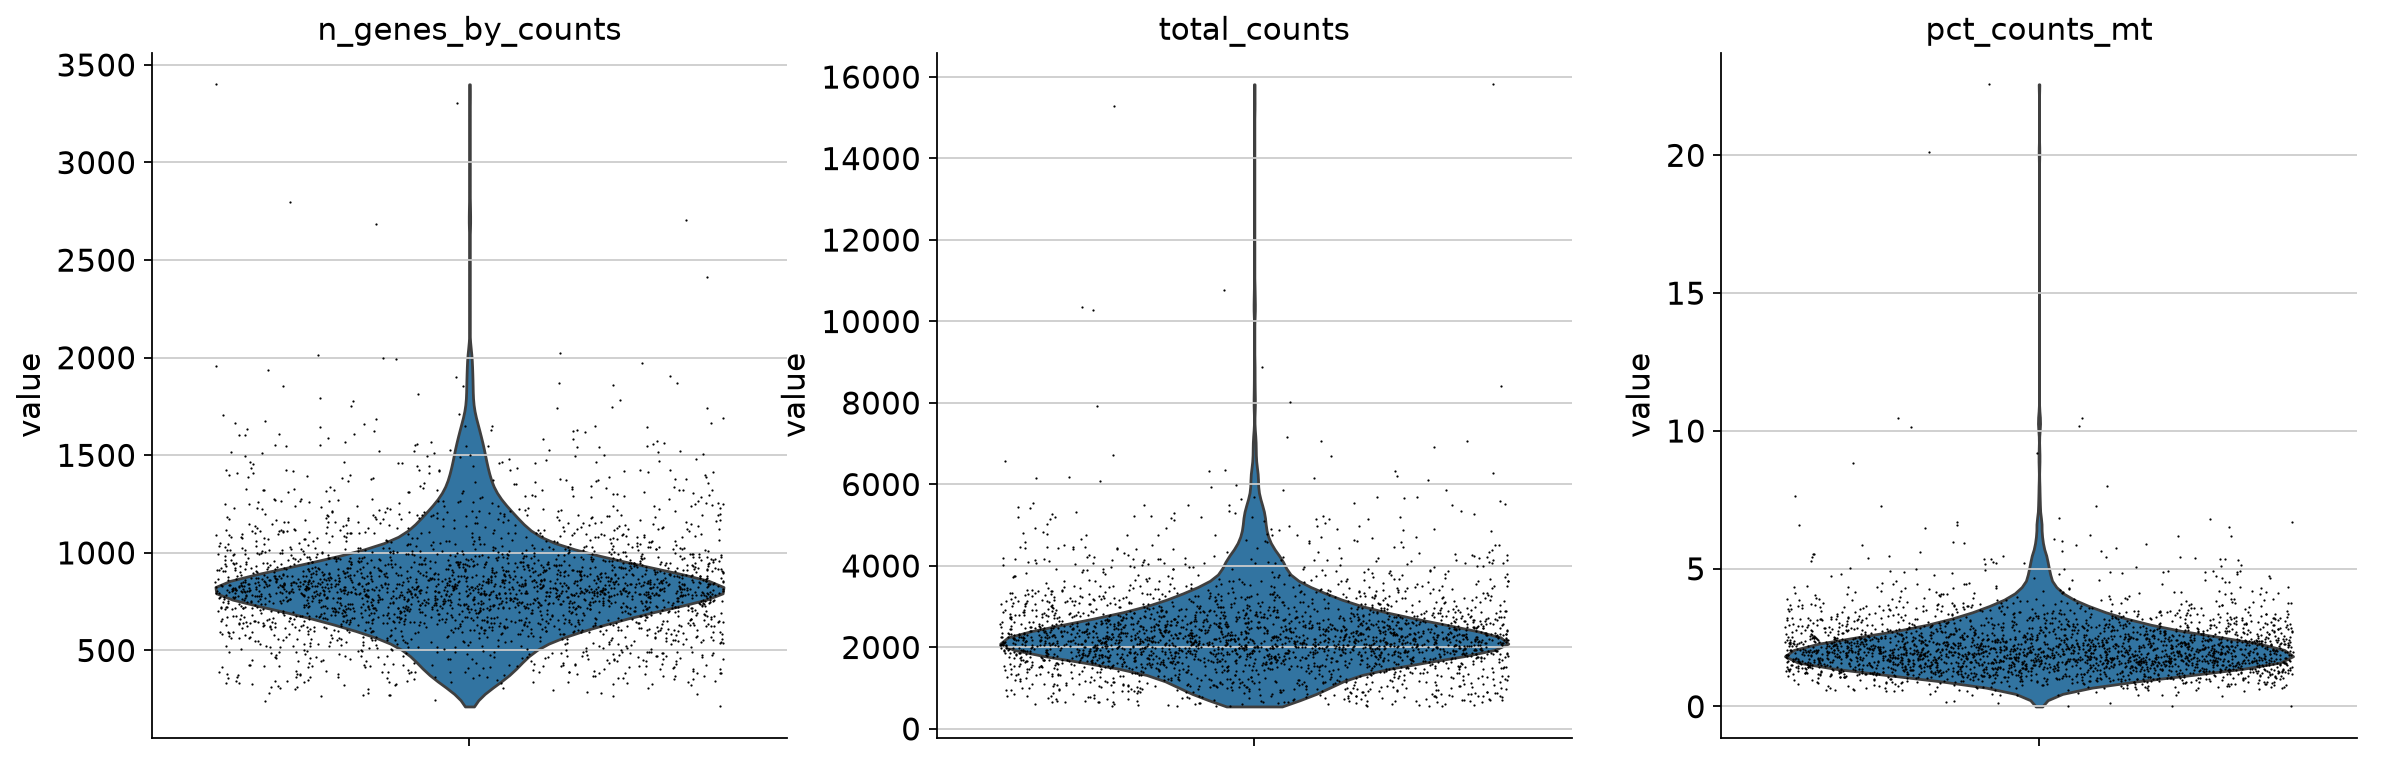

In [10]:
 # COUNT DISTRIBUTIONS -------------------------------------------------------- #
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

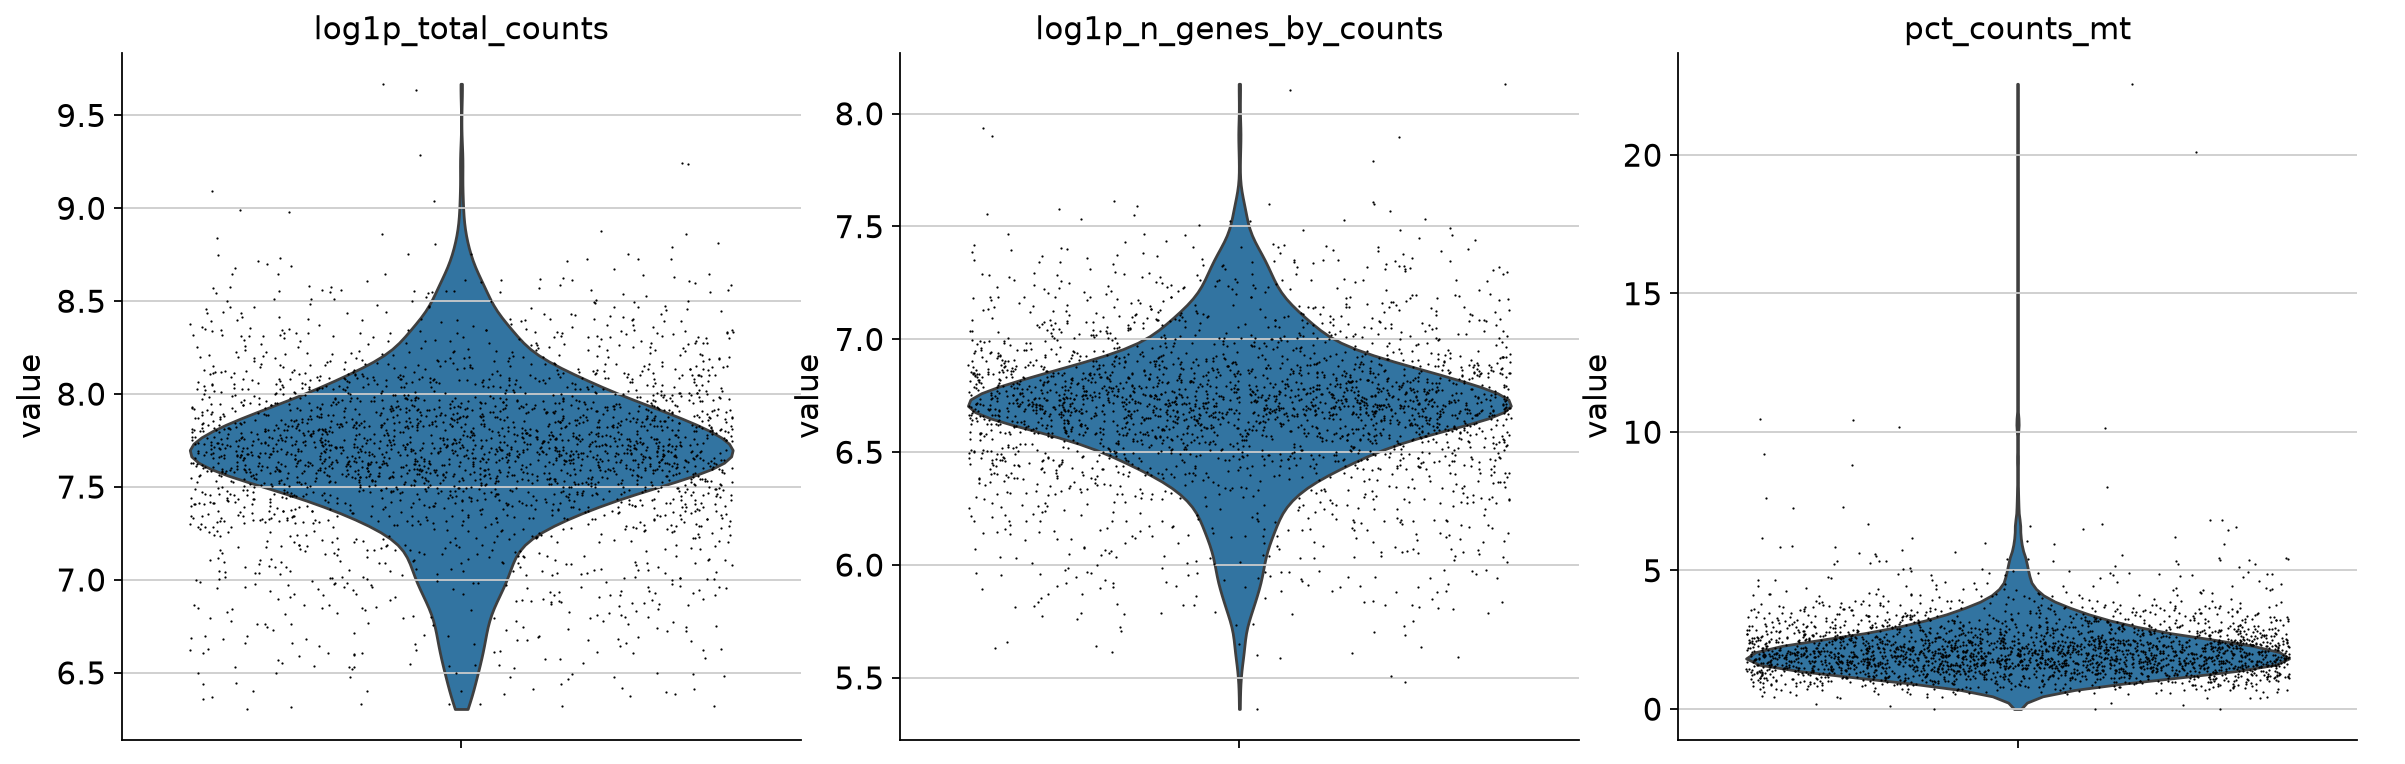

In [11]:
# LOG1P COUNT DISTRIBUTIONS -------------------------------------------------- #
sc.pl.violin(
    adata,
    ["log1p_total_counts", "log1p_n_genes_by_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

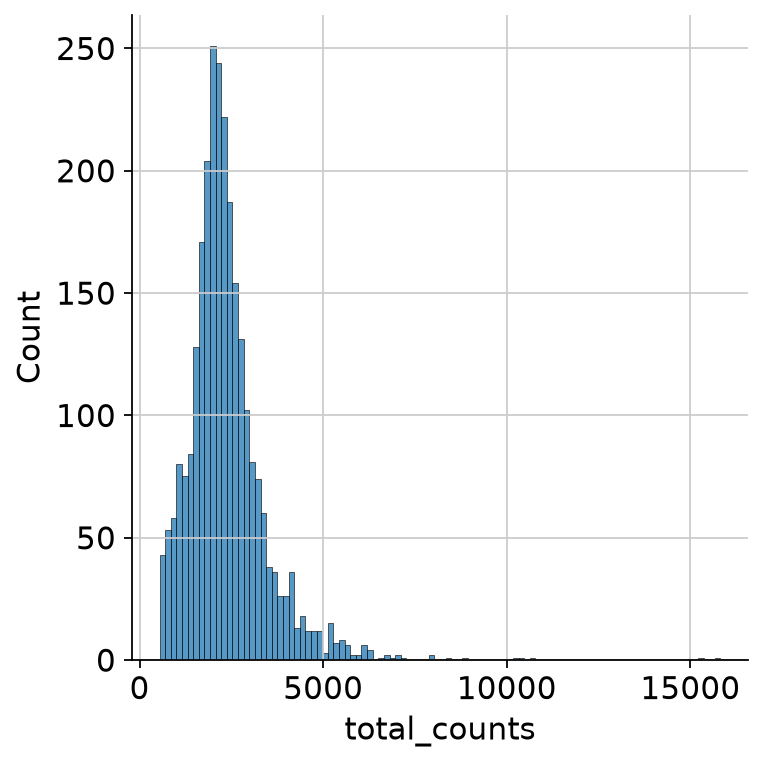

In [12]:
# DISTRIBUTION / HISTOGRAM OF TOTAL COUNTS FOR EACH CELL --------------------- #
# total_counts: total number of counts for a cell (library size)
# ---------------------------------------------------------------------------- #
p1 = sns.displot(adata.obs["total_counts"], bins=100, kde=False)
p1.savefig(experiment/'images/pbmc3k/pbmc3k_total_counts_dist.png')

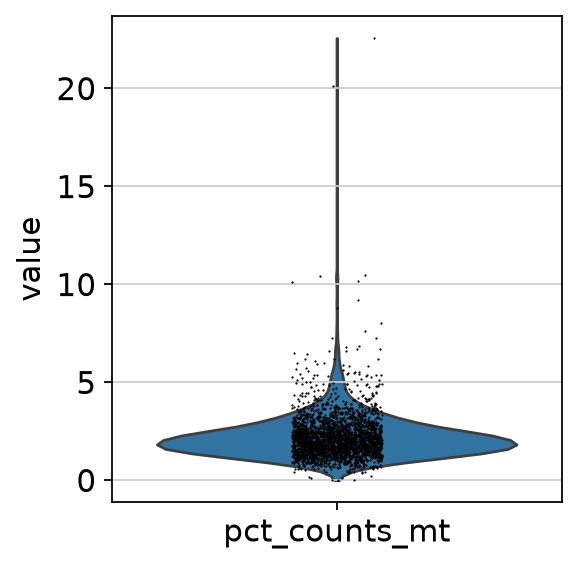

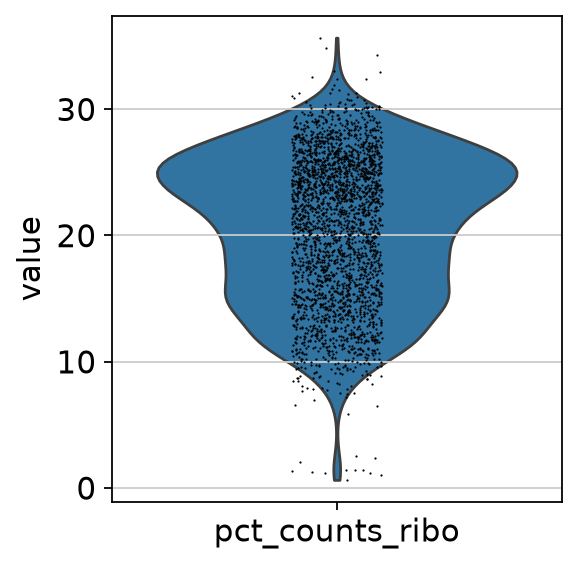

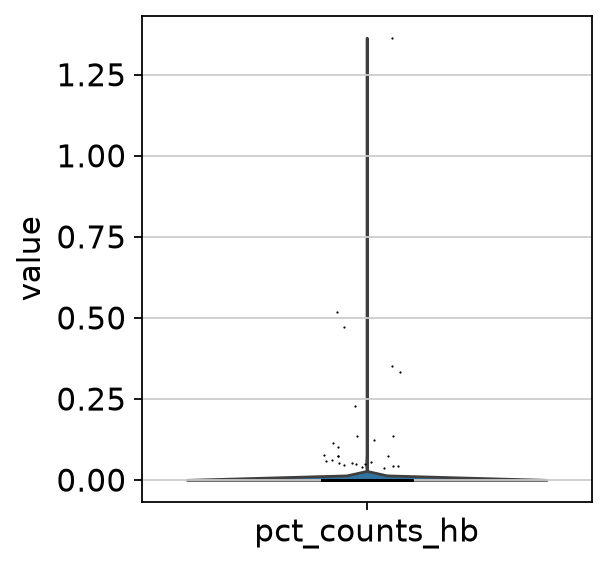

In [13]:
# MITROCHONDRIAL GENES ------------------------------------------------------- #
# pct_counts_mt: proportion of total counts for a cell which are mitochondrial
# threshold is defined by: median + n*median absolute deviation (MAD)
# ---------------------------------------------------------------------------- #
n=5

metric='pct_counts_mt'
axs = sc.pl.violin(adata,keys=metric,show=False)
plt.savefig(experiment/f'images/pbmc3k/pbmc3k_{metric}.png')
plt.show()

# RIBOSOMAL GENES ------------------------------------------------------------ #
metric='pct_counts_ribo'
axs = sc.pl.violin(adata,keys=metric,show=False)
plt.savefig(experiment/f'images/pbmc3k/pbmc3k_{metric}.png')
plt.show()

# HEMOGLOBIN GENES ----------------------------------------------------------- #
metric='pct_counts_hb'
axs = sc.pl.violin(adata,keys=metric,show=False)
plt.savefig(experiment/f'images/pbmc3k/pbmc3k_{metric}.png')
plt.show()

### define outliers

In [14]:
# OUTLIER DEFINITION --------------------------------------------------------- #
from scipy.stats import median_abs_deviation


def get_thresholds(adata, metric: str, nmads: int, round:bool=False, dtype=tuple):
    M = adata.obs[metric]
    bottom = np.median(M) - nmads * median_abs_deviation(M)
    top = np.median(M) + nmads * median_abs_deviation(M)
    if round: bottom, top = np.round(bottom,1), np.round(top,1)
    if dtype==tuple: return bottom, top
    elif dtype==str: return f'[{bottom},{top}]'
    else: dtype((bottom,top))

def is_outlier(adata, metric: str, nmads: int):
    M = adata.obs[metric]
    bottom, top = get_thresholds(adata=adata,metric=metric,nmads=nmads)
    outlier = (M < bottom) | (top < M)
    return outlier

In [15]:
# CREATE OUTLIER OBS COL ----------------------------------------------------- #
def flag_outlier_reasons(
    adata, 
    outlier_reason_map:dict,
    colors:dict|None=None,
    nmads:int=5, 
    pass_label="Pass",
    multiple_label="Multiple Metrics",
    ):
    """
    Computes outliers for metrics in outlier_reason_map and creates
    a descriptive 'outlier_reason' column in adata.obs.

    outlier threshold based on median +/- nmads * MAD
    """
    masks = {}
    for metric, caller in outlier_reason_map.items():
        masks[caller] = is_outlier(adata, metric, nmads)

    # rows: cells, columns: outlier results
    df_masks = pd.DataFrame(masks, index=adata.obs_names)
    fail_counts = df_masks.sum(axis=1) # count fails per cell
    new_lists = df_masks.apply(lambda x: [col for col,v in zip(x.index,x) if v], axis=1)

    if len(outlier_reason_map) > 1:
        multiple_strings = (
            multiple_label + " (" + fail_counts.astype(str) + ")"
        )
        new_reasons = np.where(
            fail_counts == 0, 
            pass_label,
            np.where(
                fail_counts == 1,
                df_masks.idxmax(axis=1), # Returns the column name where True is located
                # multiple_strings
                multiple_label
            )
        )
    else:
        single_metric_name = next(iter(outlier_reason_map.values()))
        new_reasons = np.where(fail_counts == 0, pass_label, single_metric_name)

    if ("outlier_reason" in adata.obs and "outlier_reason_list" in adata.obs):
        final_lists = [
            old + new for old, new in zip(adata.obs["outlier_reason_list"], new_lists)
        ]
        final_reasons = [
            pass_label if len(lst) == 0 else
            lst[0] if len(lst) == 1 else
            multiple_label
            for lst in final_lists
        ]
        old_colors = {cat:color for cat,color in zip(adata.obs["outlier_reason"].cat.categories,adata.uns['outlier_reason_colors'])}
        old_colors.update(colors)
        colors = old_colors
        adata.obs["outlier_reason"] = pd.Categorical(final_reasons, categories=list(colors))
        adata.obs["outlier_reason_list"] = final_lists
    else:
        adata.obs["outlier_reason"] = pd.Categorical(new_reasons, categories=list(colors))
        adata.obs["outlier_reason_list"] = new_lists
        # adata.obs["outlier_reason"] = pd.Categorical(reasons)
    if colors!=None: 
        adata.uns["outlier_reason_colors"] = [
            colors[cat] for cat in adata.obs["outlier_reason"].cat.categories
            ]
    return adata

def find_reason(df,search:list,mode='and',col="outlier_reason_list"):
    if not isinstance(search,list): search=[search]
    possible = np.unique(np.concatenate(outlier_reasons['outlier_reason_list'].values))
    for s in search:
        if s not in possible: print(f"search term '{s}' is not possible and will be removed.")
    search = [s for s in search if s in possible]
    if mode=='and': return df[df[col].apply(lambda x: sum(v in search for v in x)==len(search))]
    elif mode=='or': return df[df[col].apply(lambda x: any(v in search for v in x))]

In [16]:
# OUTLIER REASONS ------------------------------------------------------------ #
#  
# Count Depth: 
# Detected Genes: 
# Top 20 Genes:
# 
# Mitochondrial:
# Ribosomal:
# ---------------------------------------------------------------------------- #

PASS_LABEL = "Pass"
MULTIPLE_LABEL = "Multiple Metrics"
outlier_reason_map = {
    'log1p_total_counts':'Count Depth',
    'log1p_n_genes_by_counts':'Detected Genes',
    # 'pct_counts_in_top_20_genes':'Top 20 Genes',
    }
metric_colors = {
    PASS_LABEL: "#D3D3D3", # Light Grey
    MULTIPLE_LABEL: "#26090a", # Purple
    'Count Depth': "#E41A1C",  # Red
    'Detected Genes': "#377EB8",  # Blue
    # 'Top 20 Genes': "#FF7F00",  # Orange
}

n=5
metrics = list(zip(outlier_reason_map,[n]*len(outlier_reason_map)))
adata_plot = adata.copy()
adata_plot = flag_outlier_reasons(adata_plot,outlier_reason_map,metric_colors,nmads=n,pass_label=PASS_LABEL,multiple_label=MULTIPLE_LABEL)

outlier_reason_map = {
    'pct_counts_mt':'Mitochondrial',
    # 'pct_counts_ribo':'Ribosomal',
    }
metric_colors = {
    PASS_LABEL: "#D3D3D3", # Light Grey
    MULTIPLE_LABEL: "#26092a", # Purple
    'Mitochondrial': "#1fa115",  # Red
    # 'Ribosomal': "#f903f1",  # Red
}
n=5 # ? stricter rules like n=3
metrics = metrics+list(zip(outlier_reason_map,[n]*len(outlier_reason_map)))
adata_plot = flag_outlier_reasons(adata_plot,outlier_reason_map,metric_colors,nmads=n,pass_label=PASS_LABEL,multiple_label=MULTIPLE_LABEL)

more_metrics = ['total_counts','n_genes_by_counts']
outlier_reasons = adata_plot.obs[['outlier_reason','outlier_reason_list']+more_metrics+[m[0] for m in metrics]]

for metric,n in metrics:
    print(metric,'outliers:',is_outlier(adata,metric,n).sum(),get_thresholds(adata,metric,n,True,str))

log1p_total_counts outliers: 58 [6.599999904632568,8.800000190734863]
log1p_n_genes_by_counts outliers: 80 [5.9,7.5]
pct_counts_mt outliers: 76 [-0.699999988079071,4.699999809265137]


In [17]:
outlier_reasons.query('outlier_reason != "Pass"')

,outlier_reason,outlier_reason_list,total_counts,n_genes_by_counts,log1p_total_counts,log1p_n_genes_by_counts,pct_counts_mt
AAAGAGACGGCATT-1,Detected Genes,[Detected Genes],792.0,335,6.675823,5.817111,2.398990
AAAGATCTGGGCAA-1,Mitochondrial,[Mitochondrial],1347.0,551,7.206378,6.313548,5.939124
AAAGCAGAAGCCAT-1,Mitochondrial,[Mitochondrial],1158.0,567,7.055313,6.342121,5.094991
AACAGCACAAGAGT-1,Multiple Metrics,"[Count Depth, Detected Genes]",688.0,342,6.535241,5.837730,2.470930
AACGCCCTGCTTAG-1,Mitochondrial,[Mitochondrial],1073.0,419,6.979145,6.040255,5.405406
...,...,...,...,...,...,...,...
TTACTCGAACGTTG-1,Multiple Metrics,"[Count Depth, Detected Genes]",15287.0,3302,9.634824,8.102586,1.766207
TTAGAATGTGTAGC-1,Multiple Metrics,"[Count Depth, Detected Genes]",627.0,285,6.442540,5.655992,3.349282
TTCAAGCTTCCAAG-1,Mitochondrial,[Mitochondrial],740.0,406,6.608001,6.008813,5.540540
TTCACAACGTCTGA-1,Count Depth,[Count Depth],677.0,394,6.519147,5.978886,0.590842


In [18]:
# SAVE OUTLIER REASONS ------------------------------------------------------- #
outlier_reasons.to_csv(experiment/'results/pbmc3k/pbmc3k_outlier_reasons.csv')

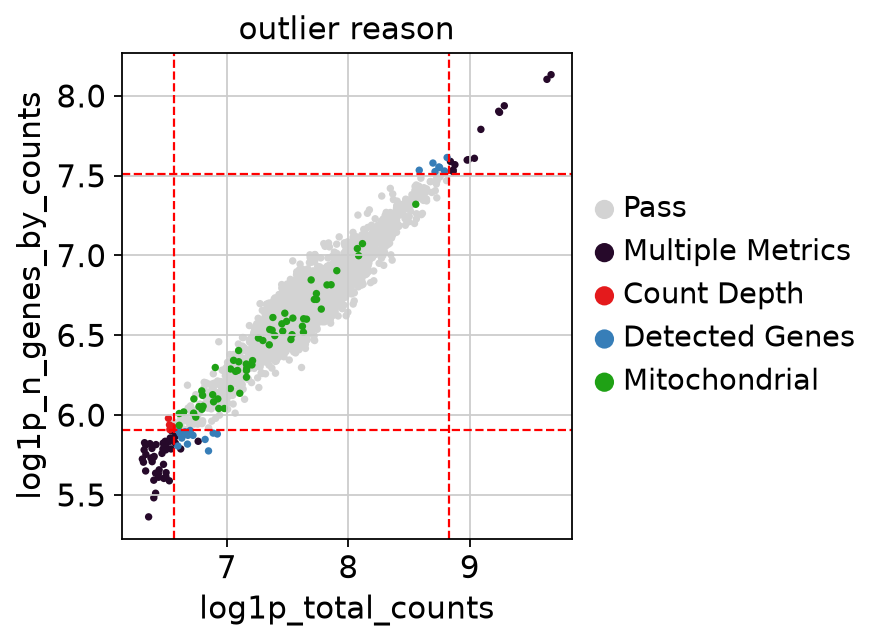

In [19]:
# PLOT OUTLIERS -------------------------------------------------------------- #

ax = sc.pl.scatter(adata_plot, "log1p_total_counts", "log1p_n_genes_by_counts",color='outlier_reason',show=False)
n=5

ax.vlines(x=get_thresholds(adata,"log1p_total_counts",n),ymin=0, ymax=1,transform=ax.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
ax.hlines(y=get_thresholds(adata,"log1p_n_genes_by_counts",n),xmin=0, xmax=1,transform=ax.get_yaxis_transform(), color='red', linestyle='--', linewidth=1)
plt.show()

# sc.pl.scatter(adata_plot, "log1p_total_counts", "pct_counts_mt",color='outlier_reason',show=False)
# sc.pl.scatter(adata_plot, "log1p_total_counts", "pct_counts_ribo",color='outlier_reason',show=False)
# ax = sc.pl.scatter(adata_plot, "log1p_total_counts", "log1p_n_genes_by_counts",show=False)

AnnData object with n_obs × n_vars = 2700 × 13714
    obs: 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier'
    var: 'gene_ids', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)
View of AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'gene_ids', 'n_cells', 'mt', 'r

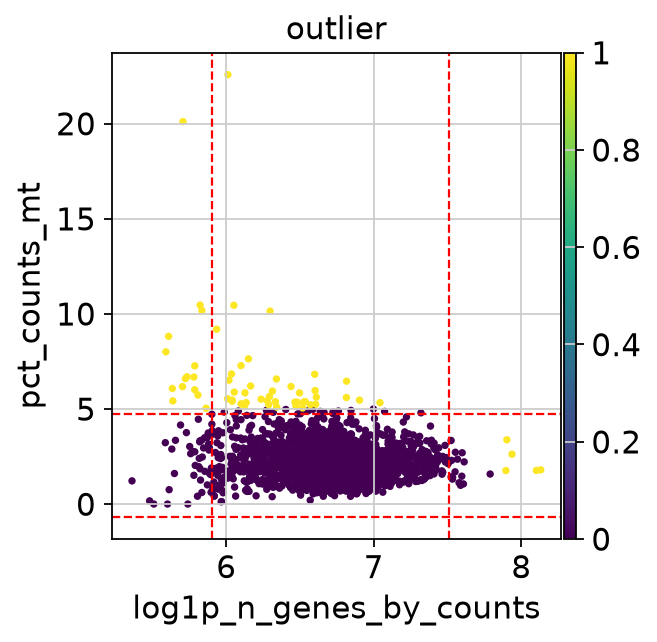

In [20]:
# DEFINE OUTLIER ------------------------------------------------------------- #
# - threshold: median +/- 5 MAD
# by read depth: flags cells with a weirdly low or weirdly high total number of RNA reads
# by detected genes: flags cells expressing too few or too many unique genes
# by mitochondrial genes: too many mitochondrial genes can indicate dying cells 
# by pct of counts in top 20 genes: flags cells where the top 20 most highly expressed genes make up an abnormally massive chunk of the total reads
# ---------------------------------------------------------------------------- #
# ! the only cells not considered an outlier are the ones that raise no flags
# search = ['Count Depth','Detected Genes','Mitochondrial']
search = ['Detected Genes','Mitochondrial']
# ---------------------------------------------------------------------------- #

adata_qc = adata.copy()

scanpy_outliers = outlier_reasons.query('n_genes_by_counts >= 2500 or n_genes_by_counts <= 200 or pct_counts_mt > 5')
outlier_cells = find_reason(outlier_reasons,search,'or')

# adata.obs['outlier'] = adata.obs.index.isin(outlier_cells.index)
# adata_qc = adata_qc[~adata_qc.obs.index.isin(outlier_cells.index)]

adata.obs['outlier'] = adata.obs.index.isin(scanpy_outliers.index)
adata_qc = adata_qc[~adata_qc.obs.index.isin(scanpy_outliers.index)]

print(adata)
print(adata_qc)



print(f"""
\nThe scanpy definition for outliers: 
n_genes_by_counts >= 2500 or n_genes_by_counts <= 200 or pct_counts_mt > 5
number of outliers: {scanpy_outliers.shape[0]}
\nMy definition for outliers:
Based on {', '.join(search)}
number of outliers: {outlier_cells.shape[0]}""")
try: 
    outlier_cells.loc[scanpy_outliers.index]
    print("""\t! Contains all outliers from scanpy definition\n""")
except:
    print("""\t! scanpy defines other outliers\n""")

ax = sc.pl.scatter(adata,"log1p_n_genes_by_counts", "pct_counts_mt",color='outlier',show=False)
n=5
ax.vlines(x=get_thresholds(adata,"log1p_n_genes_by_counts",n),ymin=0, ymax=1,transform=ax.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
ax.hlines(y=get_thresholds(adata,"pct_counts_mt",n),xmin=0, xmax=1,transform=ax.get_yaxis_transform(), color='red', linestyle='--', linewidth=1)
plt.savefig(experiment/'images/pbmc3k/pbmc3k_qc_outliers.png')
plt.show()

log1p_n_genes_by_counts outliers: 80 (np.float64(5.9), np.float64(7.5))


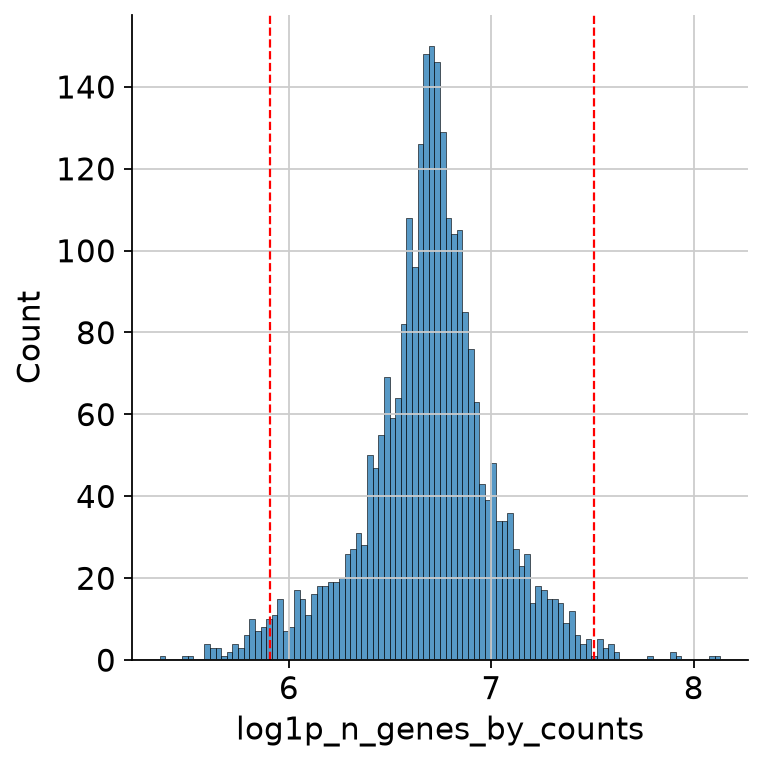

pct_counts_mt outliers: 76 (np.float32(-0.7), np.float32(4.7))


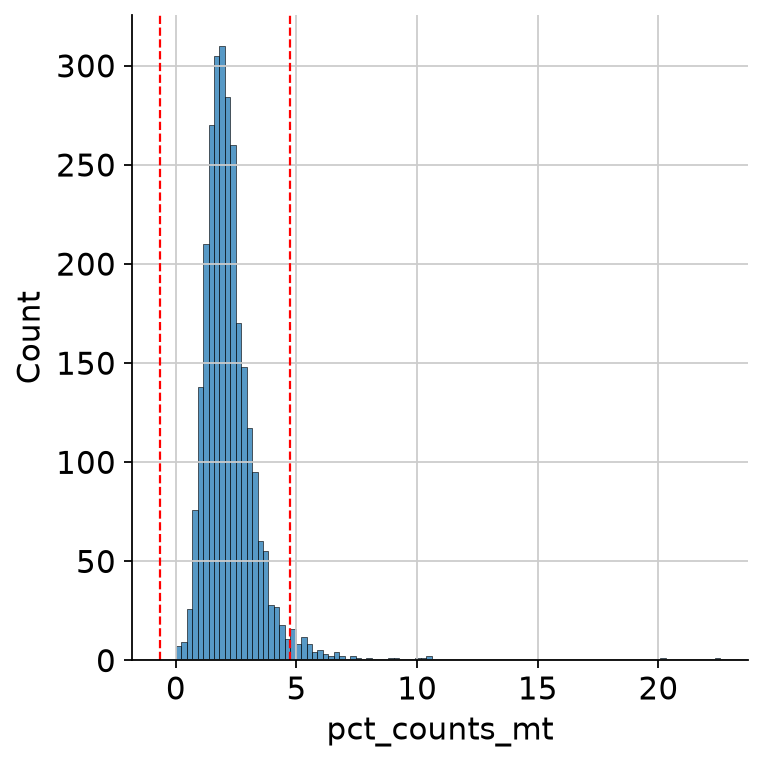

In [21]:
# PLOT REASONS --------------------------------------------------------------- #
# metric,n="pct_counts_in_top_20_genes",5
# p1 = sns.displot(adata.obs[metric], bins=100, kde=False)
# print(metric,'outliers:',is_outlier(adata,metric,n).sum(),get_thresholds(adata,metric,n,True))
# p1.ax.vlines(x=get_thresholds(adata,metric,n),ymin=0, ymax=1,transform=p1.ax.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
# plt.show()

# metric,n="log1p_total_counts",5
# p1 = sns.displot(adata.obs[metric], bins=100, kde=False)
# print(metric,'outliers:',is_outlier(adata,metric,n).sum(),get_thresholds(adata,metric,n,True))
# p1.ax.vlines(x=get_thresholds(adata,metric,n),ymin=0, ymax=1,transform=p1.ax.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
# plt.show()


metric,n="log1p_n_genes_by_counts",5
p1 = sns.displot(adata.obs[metric], bins=100, kde=False)
print(metric,'outliers:',is_outlier(adata,metric,n).sum(),get_thresholds(adata,metric,n,True))
p1.ax.vlines(x=get_thresholds(adata,metric,n),ymin=0, ymax=1,transform=p1.ax.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
plt.show()

metric,n="pct_counts_mt",5
p1 = sns.displot(adata.obs[metric], bins=100, kde=False)
print(metric,'outliers:',is_outlier(adata,metric,n).sum(),get_thresholds(adata,metric,n,True))
p1.ax.vlines(x=get_thresholds(adata,metric,n),ymin=0, ymax=1,transform=p1.ax.get_xaxis_transform(), color='red', linestyle='--', linewidth=1)
plt.show()

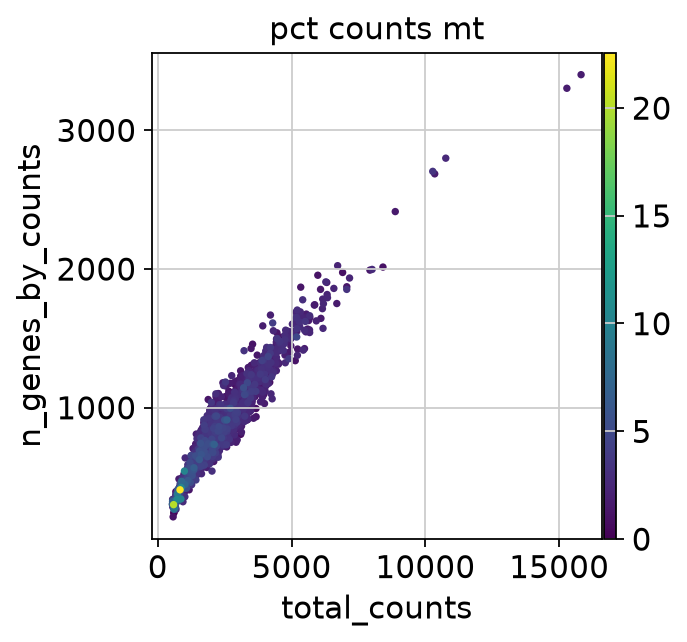

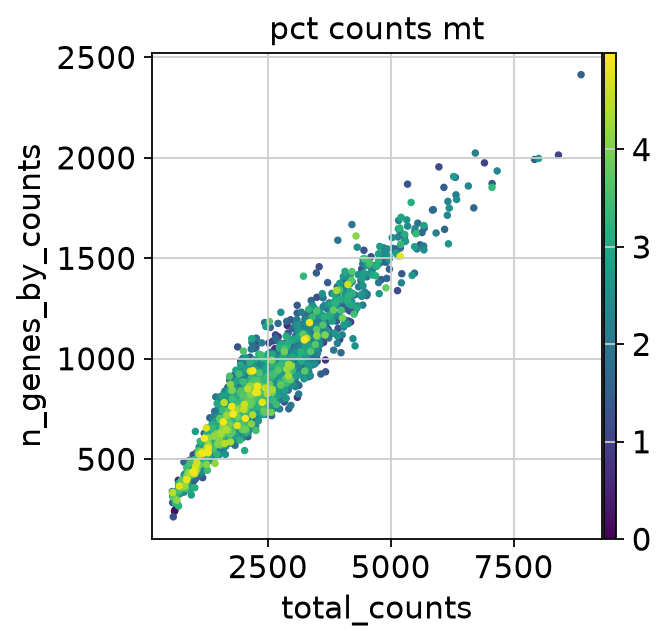

In [22]:
# COMPARE BEFORE AND AFTER --------------------------------------------------- #
# compare (for each cell) how many genes have counts (n_genes_by_counts) to the total sum of all counts (total_counts)
# also show whether dying cells (pct_counts_mt) generate less counts
# ---------------------------------------------------------------------------- #

p1 = sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt", show=False)
plt.savefig(experiment/f'images/pbmc3k/pbmc3k_qc_before.png')
plt.show()
p2 = sc.pl.scatter(adata_qc, "total_counts", "n_genes_by_counts", color="pct_counts_mt", show=False)
plt.savefig(experiment/f'images/pbmc3k/pbmc3k_qc_after.png')
plt.show()

In [23]:
# PLOT TOTAL COUNTS ---------------------------------------------------------- #
# bin_edges = np.arange(0, outlier_reasons["total_counts"].max()+200, 200)
# sns.histplot(outlier_reasons["total_counts"], bins=bin_edges, kde=False)
# sns.histplot(outlier_reasons[~outlier_reasons.index.isin(outlier_cells.index)]["total_counts"], bins=bin_edges, kde=False)
# sns.histplot(outlier_cells["total_counts"], bins=bin_edges, kde=False)

In [24]:
# RESEARCH SPECIFIC CELL ----------------------------------------------------- #
# adata_qc : outliers are removed
# adata : keeps all cells but has obs where you can see which cell would be deemed outlier
# outliers : is a anndata object that stores those exact outliers and information why its an outlier
# ---------------------------------------------------------------------------- #
cell = adata.obs.query('outlier == True').iloc[10].name
print(outlier_reasons.loc[cell][:2])
cell = adata.obs.query('outlier == True').iloc[33].name
print(outlier_reasons.loc[cell][:2])

outlier_reason           Mitochondrial
outlier_reason_list    [Mitochondrial]
Name: ACTTGTACCCGAAT-1, dtype: object
outlier_reason           Mitochondrial
outlier_reason_list    [Mitochondrial]
Name: GAATGGCTAAGATG-1, dtype: object


## Doublet Detection

Running Scrublet
normalizing counts per cell
    finished (0:00:02)
extracting highly variable genes
    finished (0:00:01)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
Embedding transcriptomes using PCA...
    using data matrix X directly
Automatically set threshold at doublet score = 0.25
Detected doublet rate = 1.2%
Estimated detectable doublet fraction = 33.8%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 3.5%
    Scrublet finished (0:00:19)
Running Scrublet
filtered out 58 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispe

/omics/odcf/analysis/OE0290_projects/heroes-aya_pools/AG_Thongjuea/Code/10x_multiomics/Selina/env/scanpy_env/lib/python3.14/site-packages/scanpy/preprocessing/_scrublet/__init__.py:297: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["doublet_score"] = scrubbed["obs"]["doublet_score"]


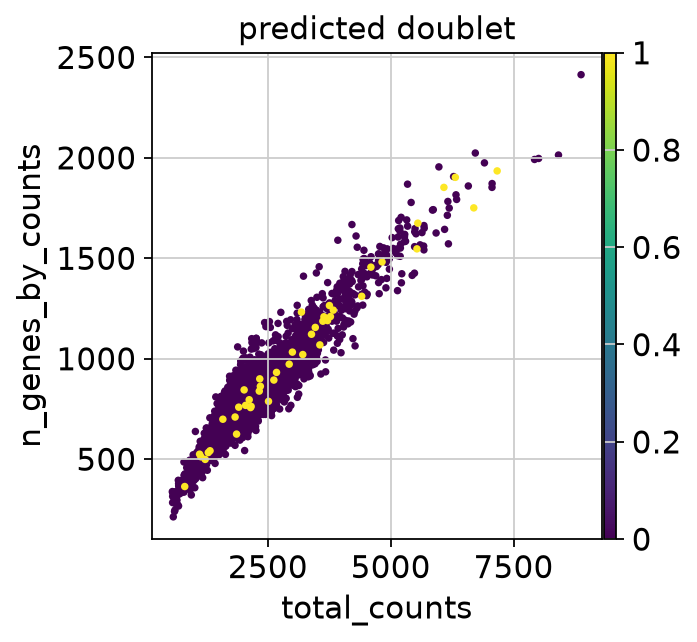

In [25]:
# DOUBLET SCORE -------------------------------------------------------------- #
# adds to adata.var:
# - highly variable
# - means
# - dispersions
# - dispersions_norm
# ---------------------------------------------------------------------------- #

sc.pp.scrublet(adata)
sc.pp.scrublet(adata_qc)

sc.pl.scatter(adata_qc, "total_counts", "n_genes_by_counts", color="predicted_doublet", show=True)

In [26]:
# PREDICTED DOUBLETS --------------------------------------------------------- #
print(adata)
adata.obs.query('predicted_doublet == True')

AnnData object with n_obs × n_vars = 2700 × 13714
    obs: 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'scrublet'
    layers: None (.X)


,n_genes,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_20_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,total_counts_ribo,log1p_total_counts_ribo,pct_counts_ribo,total_counts_hb,log1p_total_counts_hb,pct_counts_hb,outlier,doublet_score,predicted_doublet
AACTTGCTACGCTA-1,900,899,6.802395,2335.0,7.756196,25.781585,62.0,4.143135,2.655246,502.0,6.220590,21.498928,0.0,0.0,0.0,False,0.333333,True
ACATTCTGGGAACG-1,1190,1189,7.081709,3715.0,8.220403,25.679677,62.0,4.143135,1.668910,748.0,6.618739,20.134588,0.0,0.0,0.0,False,0.403141,True
ACCCAGCTGTTAGC-1,1547,1546,7.344073,5534.0,8.618847,24.557282,114.0,4.744932,2.059993,1171.0,7.066467,21.160103,0.0,0.0,0.0,False,0.283019,True
ACCCGTTGCTTCTA-1,1861,1852,7.524561,6083.0,8.713418,22.160118,87.0,4.477337,1.430215,1383.0,7.232733,22.735493,0.0,0.0,0.0,False,0.333333,True
ACGAGTACGAATCC-1,1188,1186,7.079184,3619.0,8.194229,26.056922,57.0,4.060443,1.575021,799.0,6.684612,22.077923,0.0,0.0,0.0,False,0.333333,True
ACGTCGCTCTATTC-1,699,698,6.549651,1584.0,7.368340,22.285354,54.0,4.007333,3.409091,296.0,5.693732,18.686869,0.0,0.0,0.0,False,0.506494,True
ACTGTGGATCTAGG-1,1312,1310,7.178545,4410.0,8.391857,23.582766,101.0,4.624973,2.290249,1041.0,6.948897,23.605442,0.0,0.0,0.0,False,0.333333,True
AGGGCGCTAACCAC-1,1068,1068,6.974479,3558.0,8.177235,28.527263,87.0,4.477337,2.445194,714.0,6.572283,20.067453,0.0,0.0,0.0,False,0.333333,True
ATCAACCTTTGTCT-1,838,837,6.731018,2571.0,7.852439,29.716064,49.0,3.912023,1.905873,733.0,6.598509,28.510307,0.0,0.0,0.0,False,0.283019,True
ATGCACGAGAACCT-1,895,893,6.795706,2622.0,7.872074,26.277651,35.0,3.583519,1.334859,712.0,6.569481,27.154844,0.0,0.0,0.0,False,0.283019,True


In [27]:
# SAVE ADATA FROM QC --------------------------------------------------------- #
# adata_qc = adata.copy()[(adata.obs.outlier==False) & (adata.obs.predicted_doublet==False)]
adata_qc = adata.copy()[(adata.obs.outlier==False)]
adata_qc.write_h5ad(workspace/'data/practice_adata/pbmc3k_qc.h5ad')
adata_qc

View of AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'scrublet'
    layers: None (.X)

# Normalization and Shifted Logarithm

In [28]:
# NORMALIZATION -------------------------------------------------------------- #
# Normalization + Shifted Logarithm
# Normalization: TP10K (adjust to sequencing depth)
# Shifted Logarithm: log1p (stabilize variance)
# ---------------------------------------------------------------------------- #
adata_norm = adata_qc.copy()
adata_norm.layers["counts"] = adata_norm.X.copy()
sc.pp.normalize_total(adata_norm, target_sum=1e4)
sc.pp.log1p(adata_norm)
adata_norm


normalizing counts per cell
    finished (0:00:00)


AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'doublet_score', 'predicted_doublet'
    var: 'gene_ids', 'n_cells', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'scrublet', 'log1p'
    layers: None (.X), 'counts'

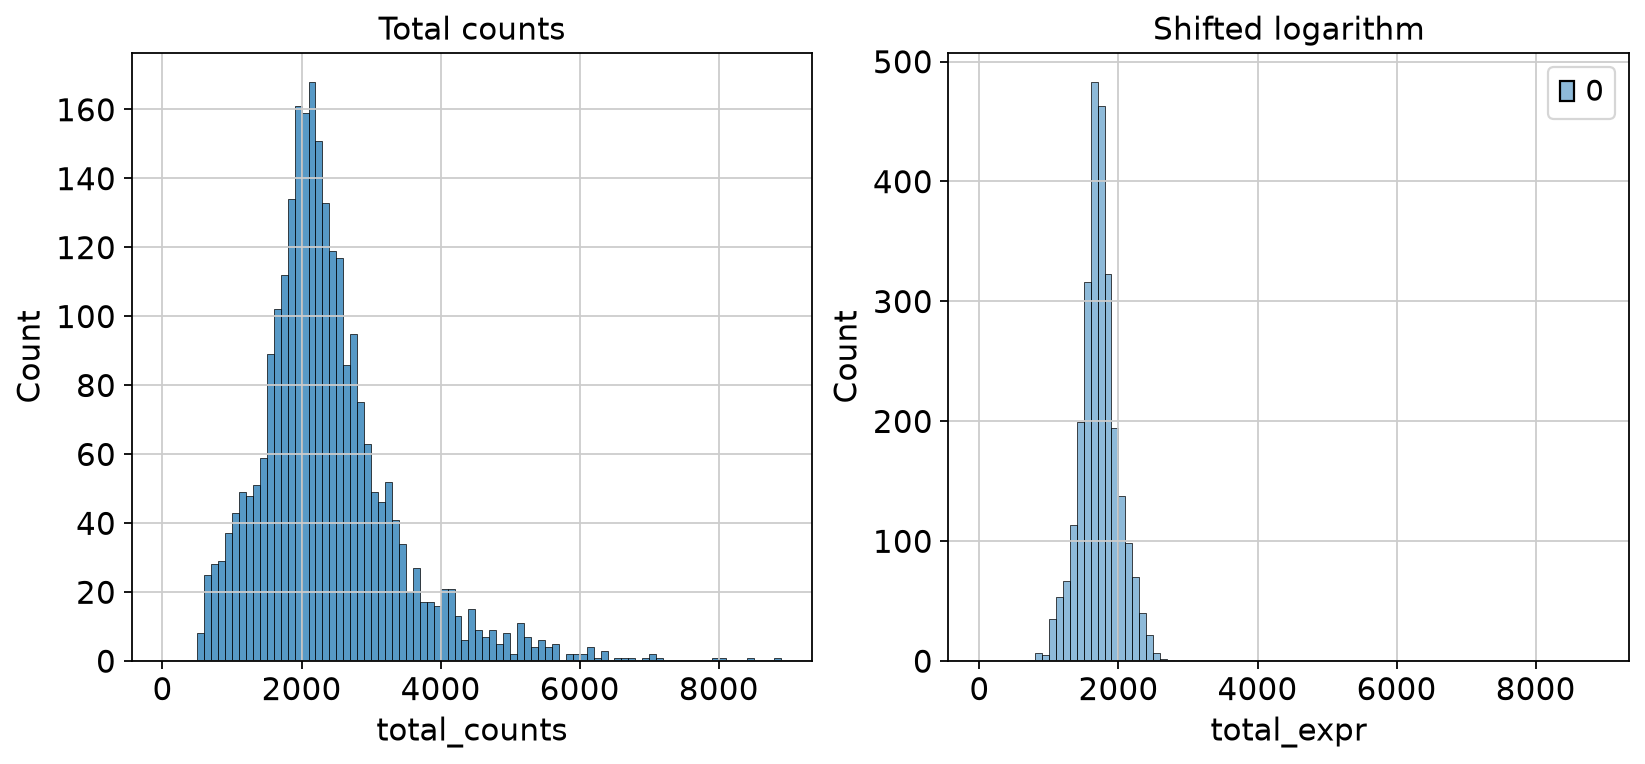

In [29]:
# PLOT TOTAL COUNTS / EXPRE PER CELL ----------------------------------------- #

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# bin_edges = np.arange(0, adata.obs["total_counts"].max()+100, 100)
# p1 = sns.histplot(adata.obs["total_counts"], bins=bin_edges, kde=False, ax=axes[0])
# axes[0].set_title("Total counts (before QC)")
bin_edges = np.arange(0, adata_norm.obs["total_counts"].max()+100, 100)
p2 = sns.histplot(adata_norm.obs["total_counts"], bins=bin_edges, kde=False, ax=axes[0])
axes[0].set_title("Total counts")
total_expr = adata_norm.layers[None].sum(1)
bin_edges = np.arange(0, adata_norm.obs["total_counts"].max()+100, 100)
p3 = sns.histplot(total_expr, bins=bin_edges, kde=False, ax=axes[1])
axes[1].set_title("Shifted logarithm")
axes[1].set_xlabel('total_expr')
plt.show()

normalizing counts per cell
    finished (0:00:00)


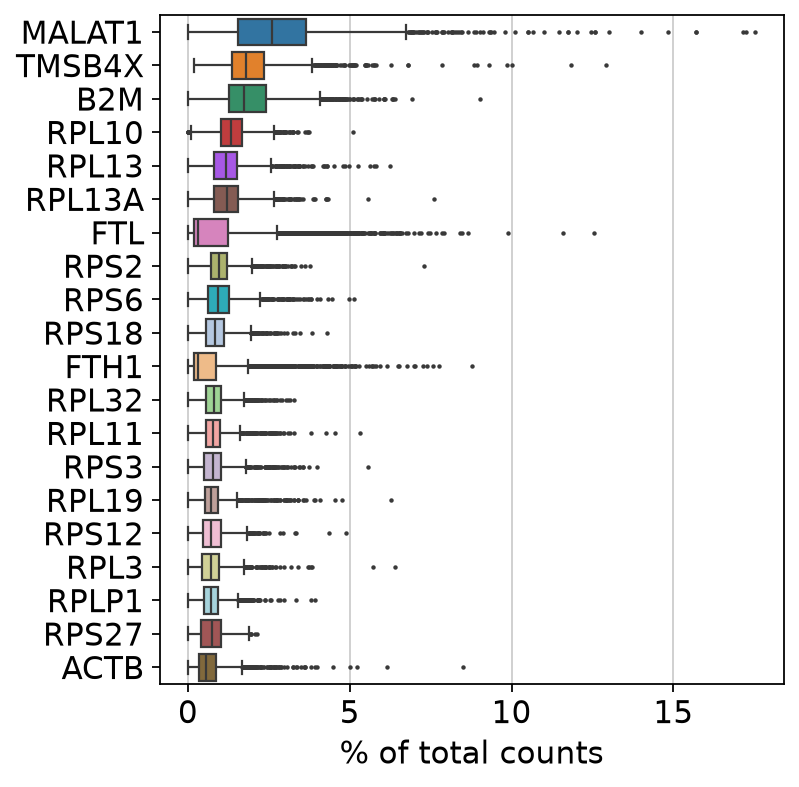

normalizing counts per cell
    finished (0:00:00)


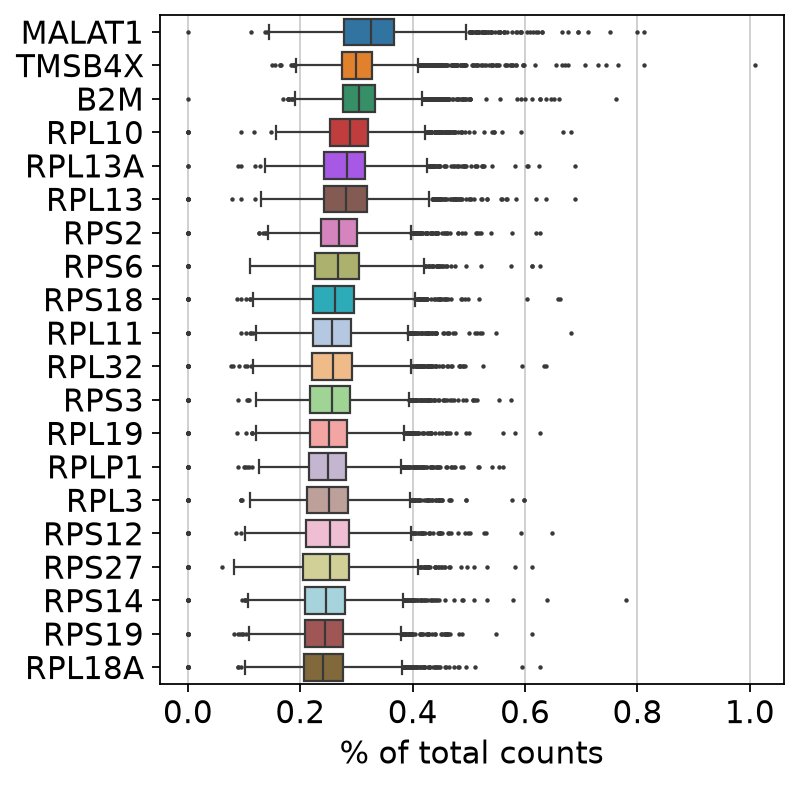

In [30]:
# HIGHEST EXPR --------------------------------------------------------------- #
sc.pl.highest_expr_genes(adata, n_top=20) # counts
sc.pl.highest_expr_genes(adata_norm, n_top=20) # normalized expression

# Feature Selection

In [31]:
# HVG METHODS ---------------------------------------------------------------- #
hvg_1 = sc.pp.highly_variable_genes(
    adata_norm,
    min_disp=0.5,
    min_mean=0.0125,
    max_mean=3,
    flavor='seurat',
    inplace = False
)
print(hvg_1.shape[0],hvg_1.query('highly_variable == True').shape[0])
hvg_2 = sc.pp.highly_variable_genes(
    adata_norm,
    n_top_genes=2000,
    flavor='seurat',
    inplace = False
)
print(hvg_2.shape[0],hvg_2.query('highly_variable == True').shape[0])
hvg_3 = sc.pp.highly_variable_genes(
    adata_norm,
    layer='counts',
    n_top_genes=2000,
    flavor='seurat_v3',
    inplace = False
)
print(hvg_3.shape[0],hvg_3.query('highly_variable == True').shape[0])

print('-'*10)

hvg_1_idx = set(hvg_1.query('highly_variable == True').index)
hvg_2_idx = set(hvg_2.query('highly_variable == True').index)
hvg_3_idx = set(hvg_3.query('highly_variable == True').index)
print(len(hvg_1_idx-hvg_2_idx))
combined = (hvg_2_idx | hvg_3_idx)
print(len(hvg_2_idx),len(hvg_3_idx))
print(len(combined))
only_hvg_3 = combined - hvg_2_idx
only_hvg_2 = combined - hvg_3_idx
combined == (only_hvg_3 | hvg_2_idx), combined == (only_hvg_2 | hvg_3_idx)
len(only_hvg_2),len(only_hvg_3)

extracting highly variable genes
    finished (0:00:00)
13714 1838
extracting highly variable genes
    finished (0:00:00)
13714 2000
extracting highly variable genes
13714 2000
----------
0
2000 2000
2495


(495, 495)

extracting highly variable genes
--> added
    'highly_variable', boolean vector (adata.var)
    'highly_variable_rank', float vector (adata.var)
    'means', float vector (adata.var)
    'variances', float vector (adata.var)
    'variances_norm', float vector (adata.var)


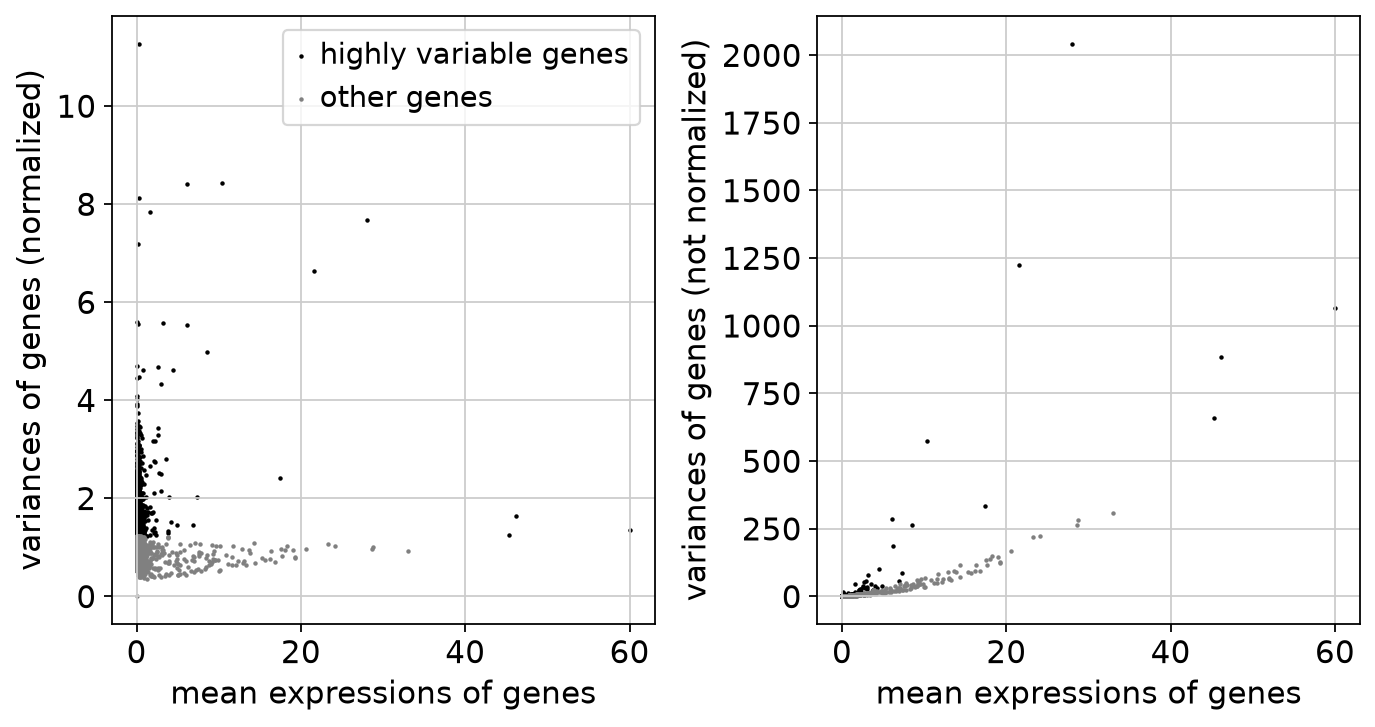

In [ ]:
# HVG DEF -------------------------------------------------------------------- #
rcParams["figure.figsize"] = (5,5)

# sc.pp.highly_variable_genes(
#     adata_norm,
#     layer='counts',
#     n_top_genes=2000,
#     flavor='seurat_v3',
# )
# sc.pl.highly_variable_genes(adata_norm)

# sc.pp.highly_variable_genes(
#     adata_norm,
#     flavor='seurat',
# )
# sc.pl.highly_variable_genes(adata_norm)

sc.pp.highly_variable_genes(
    adata_norm,
    layer='counts',
    n_top_genes=2000,
    flavor='seurat_v3',
)
sc.pl.highly_variable_genes(adata_norm)

# Dimension Reduction

## PCA: Principal Component Analysis

regressing out ['total_counts', 'pct_counts_mt']
    finished (0:00:00)
computing PCA
    with n_comps=50
    finished (0:00:07)


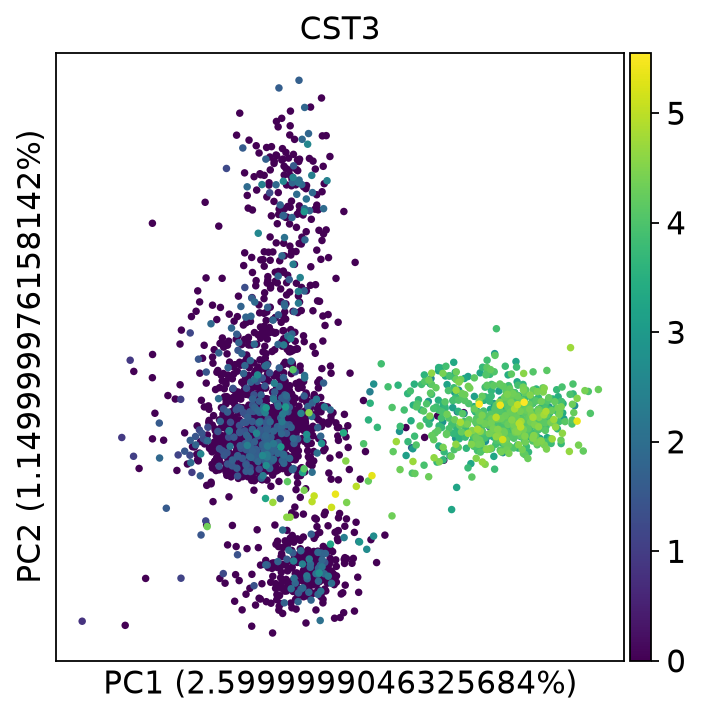

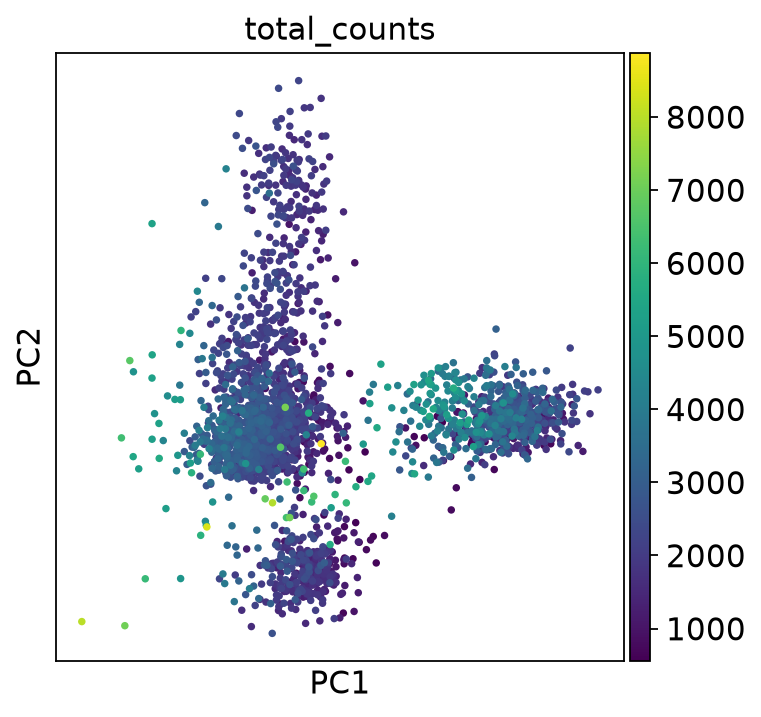

In [ ]:
# PCA ------------------------------------------------------------------------ #

adata_norm.layers["scaled"] = adata_norm.X.toarray()

os.environ["OPENBLAS_NUM_THREADS"] = "32"
os.environ["MKL_NUM_THREADS"] = "32"
os.environ["OMP_NUM_THREADS"] = "32"

sc.pp.regress_out(adata_norm, ["total_counts", "pct_counts_mt"], layer="scaled")
sc.pp.scale(adata_norm, max_value=10, layer="scaled")

sc.tl.pca(adata_norm, layer='scaled', n_comps=50, zero_center=True, mask_var="highly_variable", svd_solver='arpack')

sc.pl.pca(adata_norm, annotate_var_explained=True, color="CST3", frameon=True)
sc.pl.pca(adata_norm, color="total_counts", frameon=True)

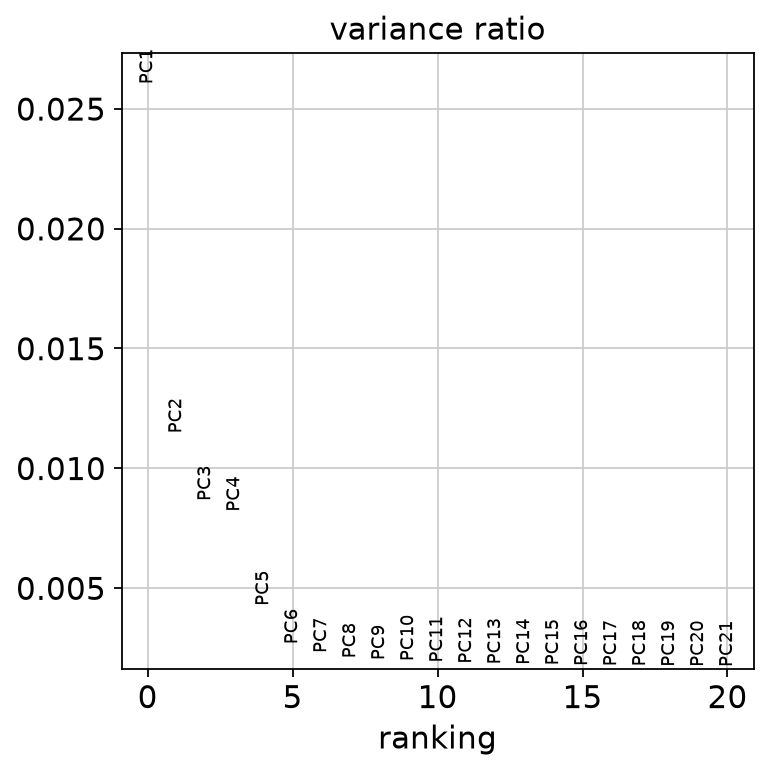

In [34]:
# VARIANCE ------------------------------------------------------------------- #
sc.pl.pca_variance_ratio(adata_norm, n_pcs=20)

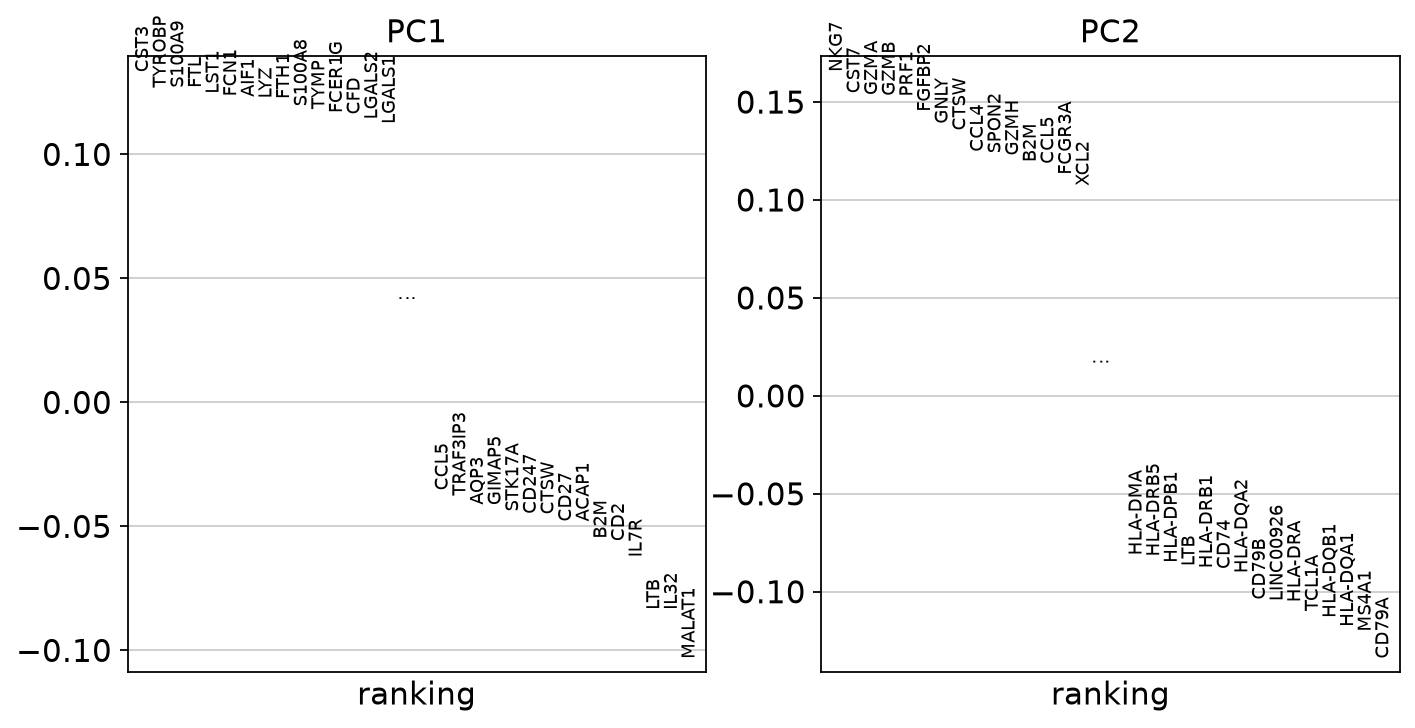

In [35]:
# PCA LOADINGS --------------------------------------------------------------- #
sc.pl.pca_loadings(adata_norm, components=(1, 2), include_lowest=True)

# Neighborhood graph

In [36]:
# NEIGHBORHOOD --------------------------------------------------------------- #
sc.pp.neighbors(adata_norm, n_neighbors=10, n_pcs=40, use_rep='X_pca')

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:15)


In [37]:
sc.tl.leiden(adata_norm, flavor='igraph',resolution=1,random_state=0,n_iterations=2,directed=False)
sc.tl.leiden(adata_norm, flavor='igraph',resolution=0.5,random_state=0,n_iterations=2,directed=False)

running Leiden clustering
    finished: found 9 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)
running Leiden clustering
    finished: found 7 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


In [38]:
# LEIDEN CLUSTERING ---------------------------------------------------------- #
sc.tl.leiden(adata_norm, flavor='igraph',resolution=0.7,random_state=0,n_iterations=2,directed=False)

running Leiden clustering
    finished: found 8 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:03)


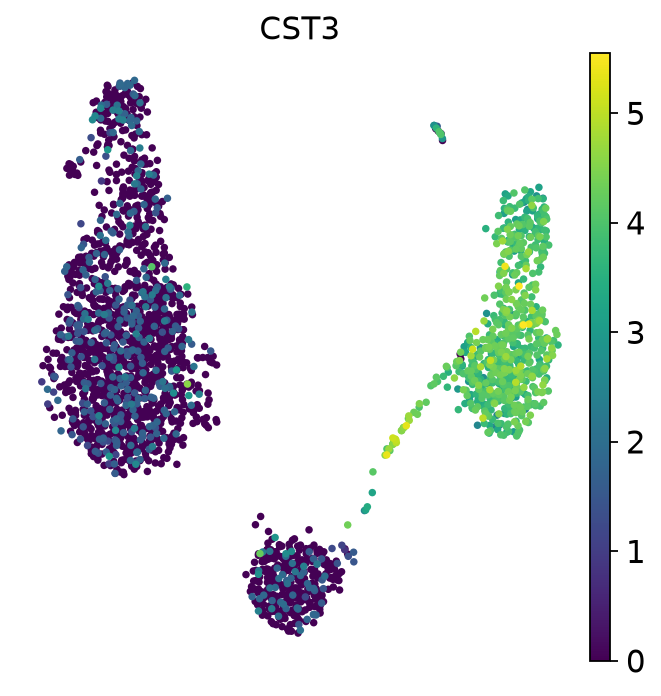

In [39]:
# UMAP SIMPLE ---------------------------------------------------------------- #
sc.tl.umap(adata_norm)
sc.pl.umap(adata_norm, color=["CST3"])

running PAGA
    finished: added
    'paga/connectivities', connectivities adjacency (adata.uns)
    'paga/connectivities_tree', connectivities subtree (adata.uns) (0:00:00)
--> added 'pos', the PAGA positions (adata.uns['paga'])
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:02)


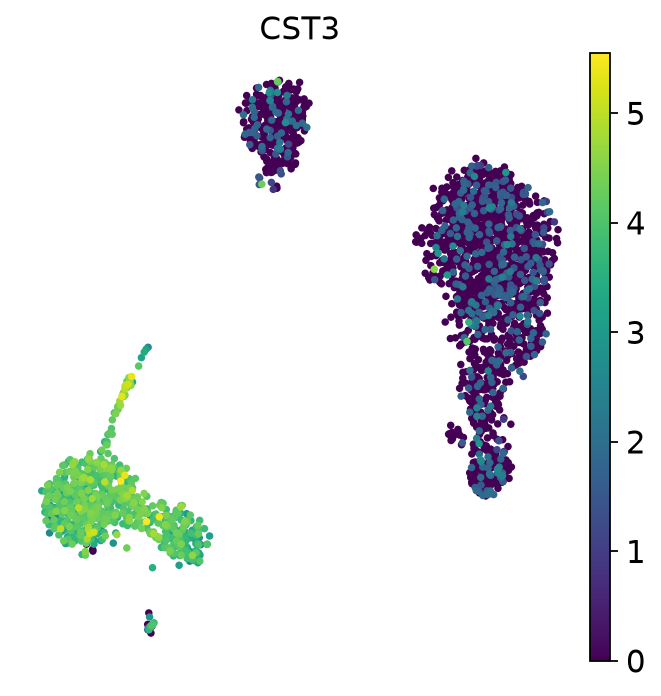

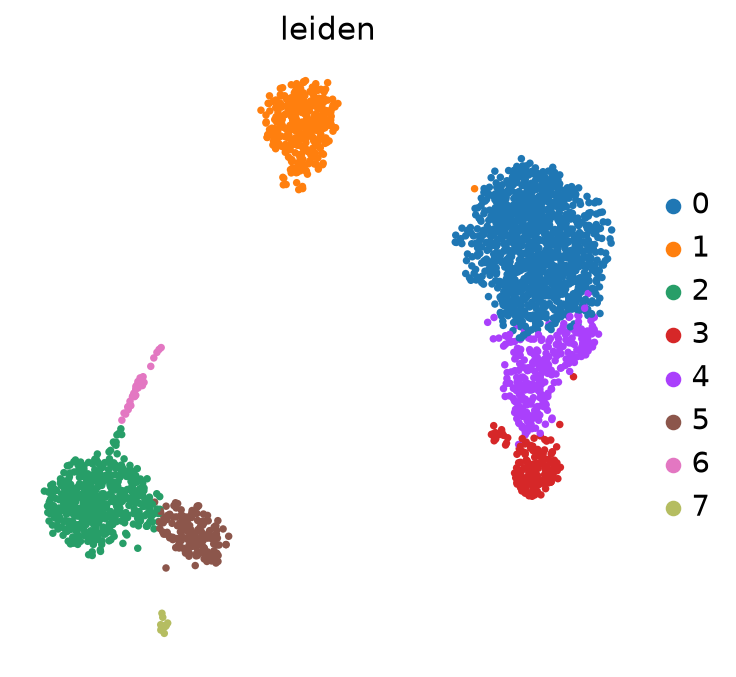

In [40]:
# UMAP WITH PAGA ------------------------------------------------------------- #

sc.tl.paga(adata_norm)
sc.pl.paga(adata_norm, plot=False)

sc.tl.umap(adata_norm, init_pos='paga')
sc.pl.umap(adata_norm, color="CST3")
sc.pl.umap(adata_norm, color="leiden")

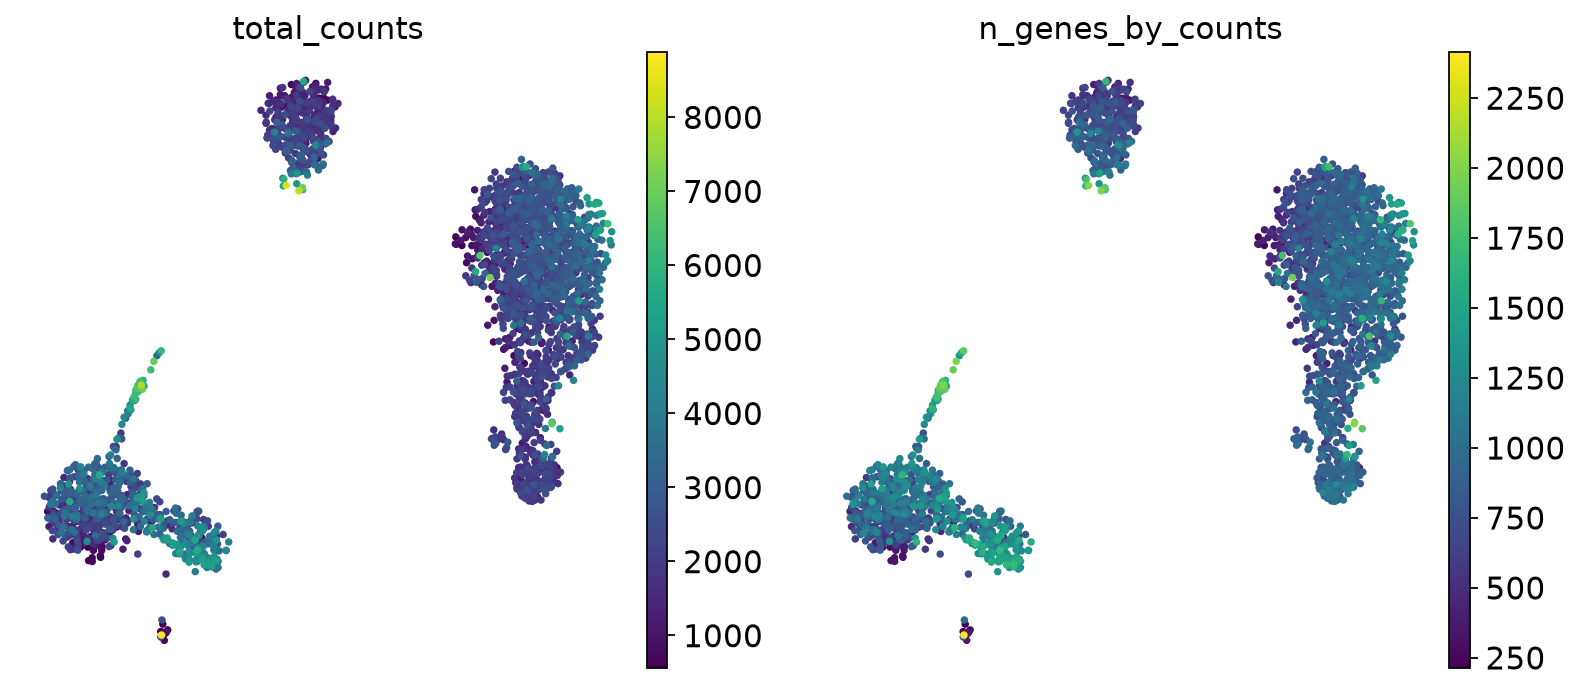

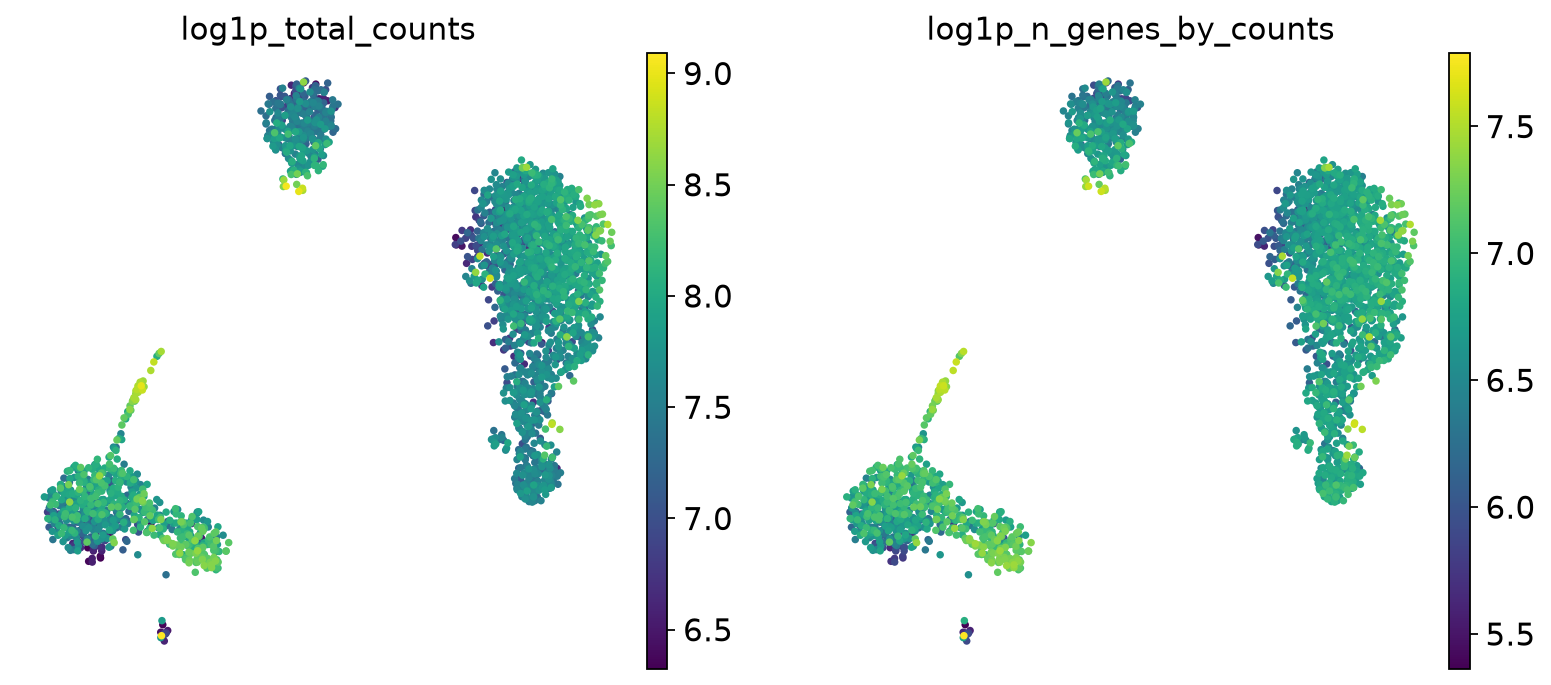

In [41]:
# UMAP QC METRICS ------------------------------------------------------------ #
sc.pl.umap(adata_norm, color=["total_counts",'n_genes_by_counts'])
sc.pl.umap(adata_norm, color=["log1p_total_counts",'log1p_n_genes_by_counts'])
# pct_counts_in_top_20_genes

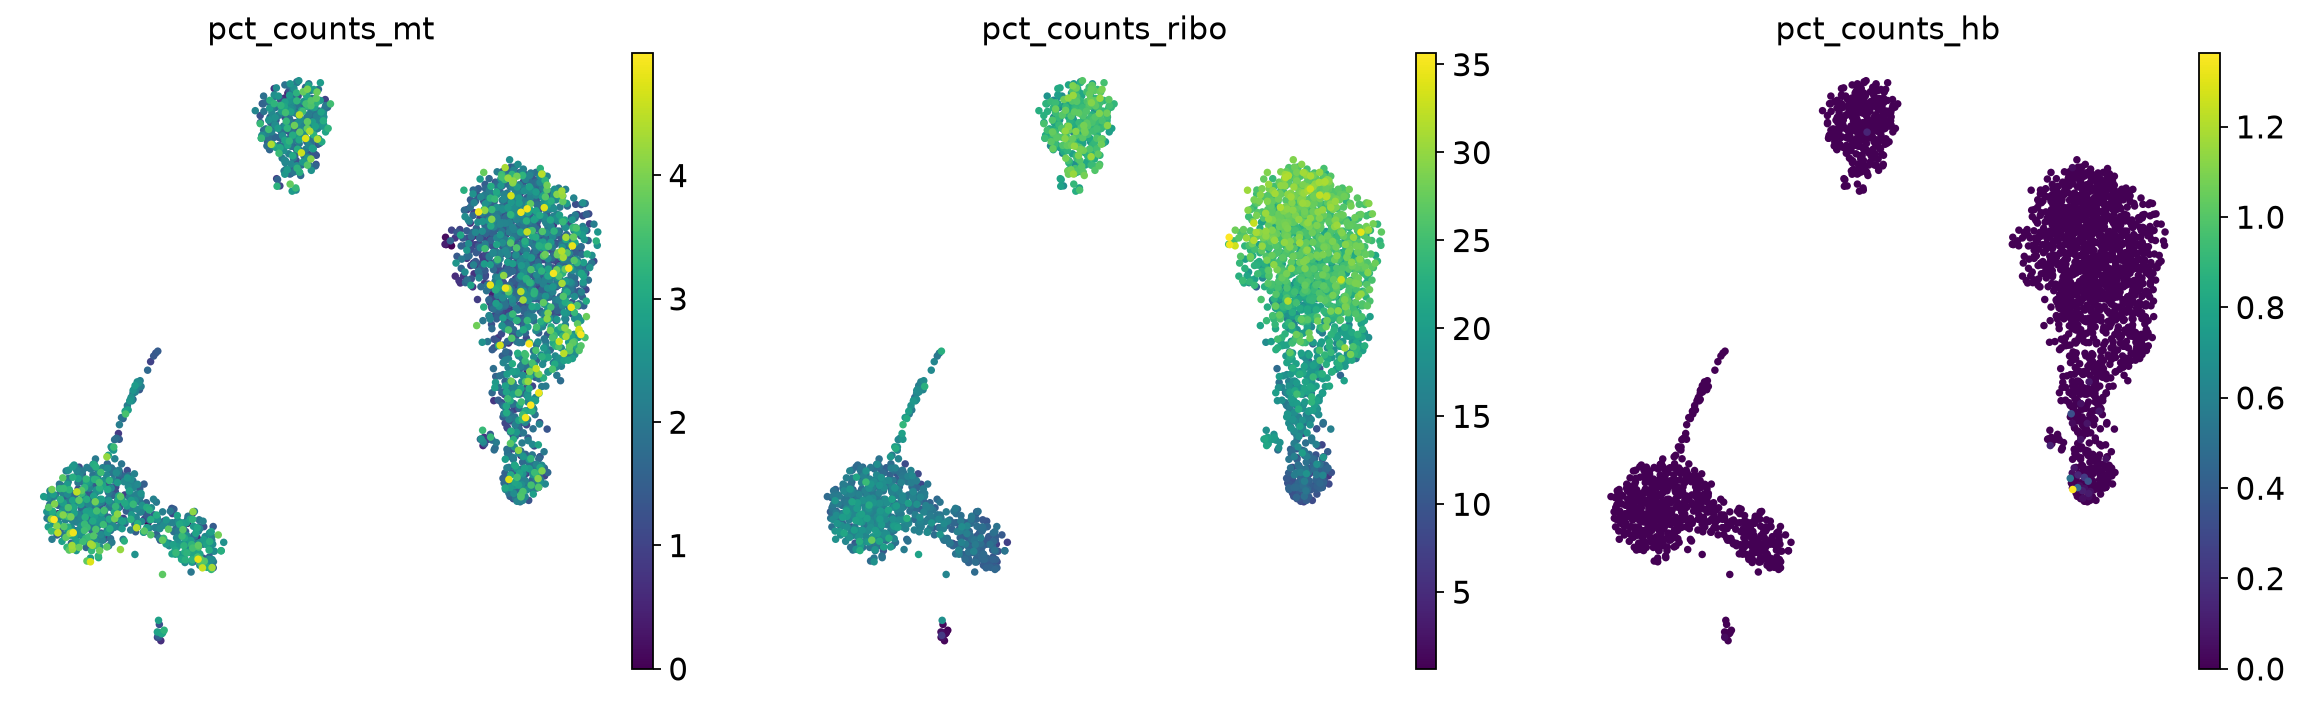

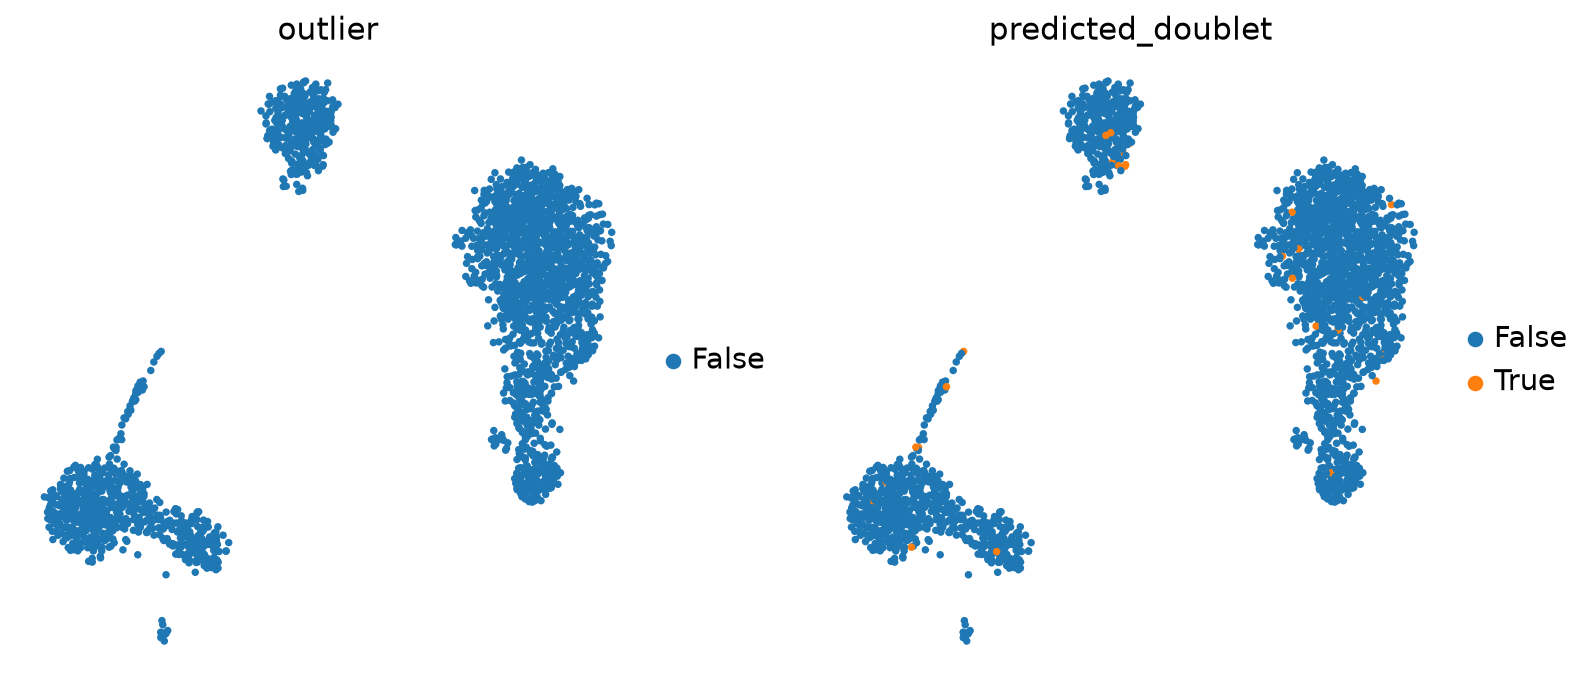

In [42]:
# UMAP QC METRICS ------------------------------------------------------------ #
sc.pl.umap(adata_norm, color=['pct_counts_mt','pct_counts_ribo','pct_counts_hb'])
sc.pl.umap(adata_norm, color=['outlier','predicted_doublet'])

# Marker Genes

In [43]:
# CHARACTERISTIC GENES FOR GROUPS -------------------------------------------- #

# sc.tl.rank_genes_groups(
#     adata_norm,
#     groupby='leiden',
#     mask_var='highly_variable',
#     method='t-test'  # FAST
# )
# sc.pl.rank_genes_groups(adata_norm, n_genes=25, sharey=False)

# sc.tl.rank_genes_groups(
#     adata_norm, 
#     groupby="leiden",
#     mask_var="highly_variable", 
#     method="logreg", # logistic regression: multi-variate appraoch
#     max_iter=1000,
#     groups='all',
#     reference='rest'
#     )
# sc.pl.rank_genes_groups(adata_norm, n_genes=25, sharey=False)


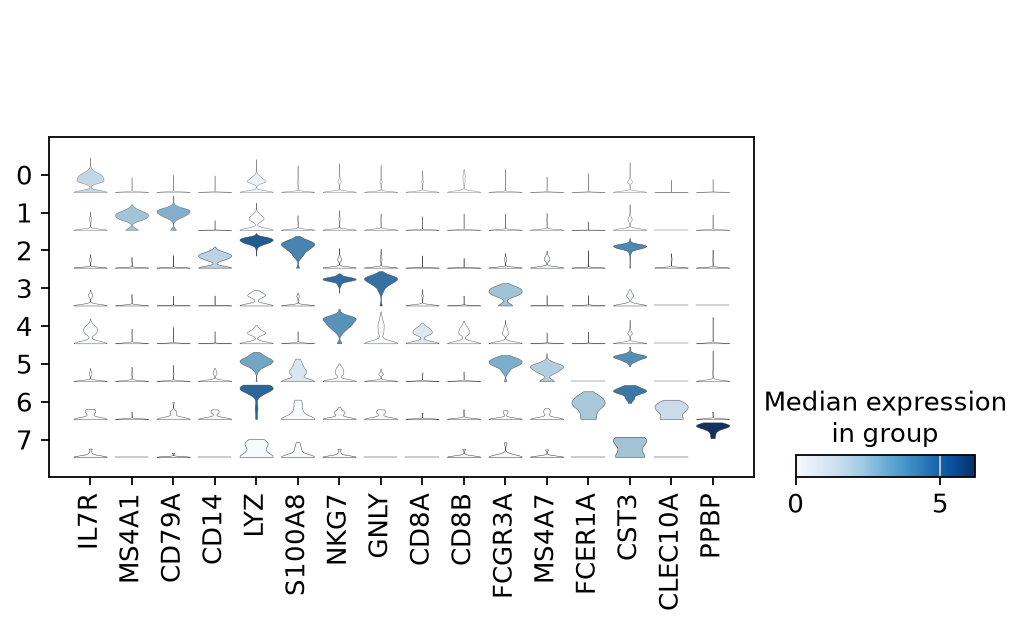

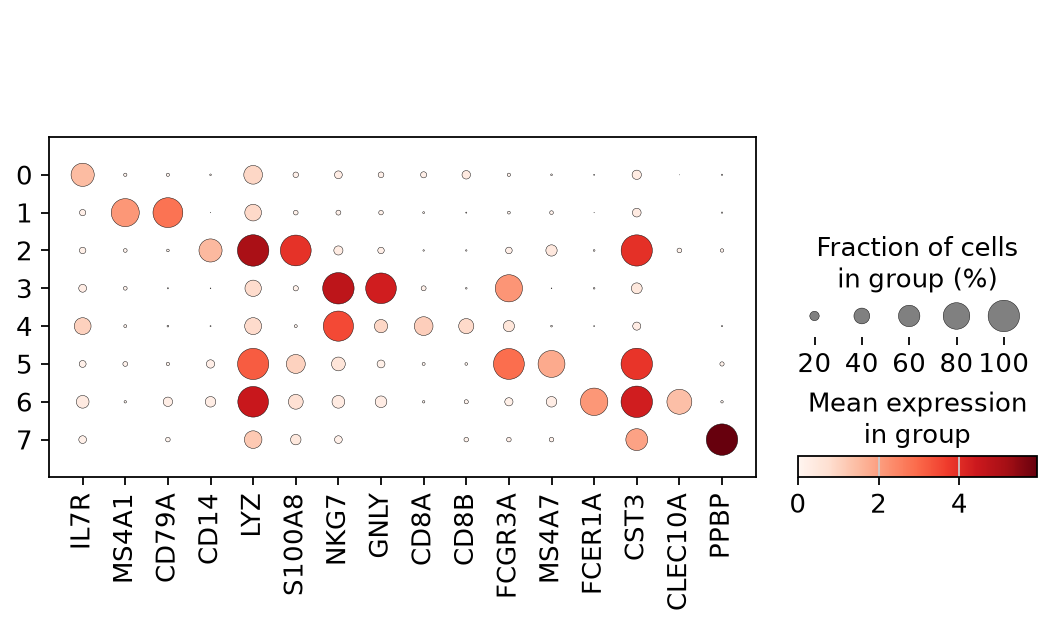

In [44]:
# SOME MARKER GENES ---------------------------------------------------------- #
# IL7R - CD4 T cells
# MS4A1 - B cells
# CD14, LYZ - CD14+ Monocytes
# CD8A - CD8 T cells
# GNLY, NKG7 - NK cells
# FCGR3A, MS4A7 - FCGR3A+ Monocytes
# FCER1A, CST3 - Dendritic Cells
# PPBP - Megakaryocytes
# ---------------------------------------------------------------------------- #
marker_genes = [
    *["IL7R", "CD79A", "MS4A1", "CD8A", "CD8B", "LYZ", "CD14"],
    *["LGALS3", "S100A8", "GNLY", "NKG7", "KLRB1"],
    *["FCGR3A", "MS4A7", "FCER1A", "CST3", "PPBP"],
]

marker_genes = {
    "CD4 T" : ['IL7R'],
    "B" : ['MS4A1','CD79A'],
    "CD14+ Monocytes" : ['CD14','LYZ','S100A8'],
    "NK" : ['NKG7','GNLY'],
    "CD8 T" : ['CD8A','CD8B'],
    "FCGR3A+ Monocytes" : ['FCGR3A','MS4A7'],
    "Dendritic" : ['FCER1A','CST3','CLEC10A'],
    "Megakaryocytes" : ['PPBP'],
    # "More" : ['LGALS3','KLRB1']
}

sc.set_figure_params(scanpy=True)
sc.pl.stacked_violin(adata_norm, [g for v in marker_genes.values() for g in v], groupby="leiden",dodge=False)
sc.pl.dotplot(adata_norm, [g for v in marker_genes.values() for g in v], groupby="leiden")


In [45]:
# CELLTYPES BASED ON SC.TL.SCORE_GENES --------------------------------------- #

def find_optimum(gene_scores,group,idx=0):
    prediction = gene_scores.loc[group].sort_values(ascending=False).index[idx]
    confirm =  markers[prediction].sort_values(ascending=False).index[0]
    if confirm == group:
        return prediction
    else:
        return find_optimum(gene_scores,group,idx=idx+1)

sc.settings.verbosity = 1

adata_an = adata_norm.copy()
for celltype,genes in marker_genes.items():
    sc.tl.score_genes(adata_an, gene_list=genes, score_name=celltype,)

markers = adata_an.obs.groupby('leiden')[list(marker_genes.keys())].mean()
new_names = {gr: find_optimum(markers,gr) for gr in adata_an.obs.leiden.cat.categories}
print('\n'.join([f'{k} : {v}' for k,v in new_names.items()]))

0 : CD4 T
1 : B
2 : CD14+ Monocytes
3 : NK
4 : CD8 T
5 : FCGR3A+ Monocytes
6 : Dendritic
7 : Megakaryocytes


In [46]:
adata_an.obs.query("B != 0")

,n_genes,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_20_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,total_counts_ribo,...,predicted_doublet,leiden,CD4 T,B,CD14+ Monocytes,NK,CD8 T,FCGR3A+ Monocytes,Dendritic,Megakaryocytes
AAACATACAACCAC-1,781,779,6.659294,2419.0,7.791523,28.234808,73.0,4.304065,3.017776,599.0,...,False,0,1.553406,-0.187215,-0.245677,-0.790968,1.800344,-0.133541,-0.422484,-0.065435
AAACATTGAGCTAC-1,1352,1352,7.210080,4903.0,8.497807,26.147257,186.0,5.231109,3.793596,1176.0,...,False,1,0.338201,1.750777,-0.295861,-0.394245,-0.297617,-0.433633,-0.067790,-0.022234
AAACATTGATCAGC-1,1131,1129,7.029973,3147.0,8.054523,27.899587,28.0,3.367296,0.889736,568.0,...,False,0,0.223319,-0.633810,-0.271860,-0.222126,-0.474177,-0.483854,-0.015214,-0.171569
AAACCGTGCTTCCG-1,960,960,6.867974,2639.0,7.878534,24.554756,46.0,3.850148,1.743085,398.0,...,False,2,-1.690758,-0.442234,1.358425,-0.203808,-0.313080,1.718450,0.949171,1.472404
AAACCGTGTATGCG-1,522,521,6.257668,980.0,6.888573,34.081633,12.0,2.564949,1.224490,100.0,...,False,3,-0.635678,-0.302903,-0.623137,3.468412,-0.241628,-0.221903,-0.489654,-0.048326
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTCGAACTCTCAT-1,1155,1153,7.050989,3459.0,8.149024,24.255565,73.0,4.304065,2.110436,528.0,...,False,2,-1.684304,-0.459150,2.736857,-0.367869,-0.217387,-0.405199,1.893299,-0.027173
TTTCTACTGAGGCA-1,1227,1224,7.110696,3443.0,8.144389,23.119373,32.0,3.496508,0.929422,729.0,...,False,1,0.028400,1.910592,-1.017980,-1.017980,-0.321910,-0.423844,-0.063780,-0.147334
TTTCTACTTCCTCG-1,622,622,6.434547,1684.0,7.429521,27.731591,37.0,3.637586,2.197150,405.0,...,False,1,-1.225527,2.319477,-0.757987,-0.757987,-0.116223,-0.243499,-0.419240,-0.077482
TTTGCATGAGAGGC-1,454,452,6.115892,1022.0,6.930495,33.463796,21.0,3.091043,2.054795,170.0,...,False,1,-0.797134,3.653097,-0.660773,-0.660773,-0.047563,-0.097067,-0.326459,-0.060476


In [47]:
# adata_an.obs.groupby('leiden')[list(xzmarker_genes.keys())].mean()
print(markers.loc["0"])
groupby = adata_an.obs.groupby('leiden')[list(marker_genes.keys())]
# print(groupby.count().loc["0"])
print(groupby.agg(lambda x: x.index).loc["0"])

CD4 T                0.394347
B                   -0.288812
CD14+ Monocytes     -0.449205
NK                  -0.593147
CD8 T                0.065374
FCGR3A+ Monocytes   -0.235653
Dendritic           -0.316605
Megakaryocytes      -0.040127
Name: 0, dtype: float64
CD4 T                [AAACATACAACCAC-1, AAACATTGATCAGC-1, AAACGCACT...
B                    [AAACATACAACCAC-1, AAACATTGATCAGC-1, AAACGCACT...
CD14+ Monocytes      [AAACATACAACCAC-1, AAACATTGATCAGC-1, AAACGCACT...
NK                   [AAACATACAACCAC-1, AAACATTGATCAGC-1, AAACGCACT...
CD8 T                [AAACATACAACCAC-1, AAACATTGATCAGC-1, AAACGCACT...
FCGR3A+ Monocytes    [AAACATACAACCAC-1, AAACATTGATCAGC-1, AAACGCACT...
Dendritic            [AAACATACAACCAC-1, AAACATTGATCAGC-1, AAACGCACT...
Megakaryocytes       [AAACATACAACCAC-1, AAACATTGATCAGC-1, AAACGCACT...
Name: 0, dtype: object


In [48]:
# COMPARE ONE AGAINST ALL ---------------------------------------------------- #

sc.tl.rank_genes_groups(
    adata_norm, 
    groupby="leiden",
    # mask_var="highly_variable", 
    method="wilcoxon",
    groups='all',
    reference='rest'
    )

rank_genes_groups_df = {}
for group in adata_norm.obs.leiden.cat.categories:
    df = sc.get.rank_genes_groups_df(adata_norm,group=group)
    rank_genes_groups_df[group] = df

# print(pd.DataFrame(adata_norm.uns["rank_genes_groups"]["names"]).head(5))
# ranks_scores = pd.concat([rank_genes_groups_df[i].rename(columns={'names':f'{i}_names','scores':f'{i}_scores'}) for i in rank_genes_groups_df],axis=1)

# CELLTYPES BASED ON SC.TL.RANK_GENES_GROUPS --------------------------------- #

scores = {}
for celltype, genes in marker_genes.items():
    scores[celltype] = {}
    predicted = []
    for gene in genes:
        score_list = []
        for gr in rank_genes_groups_df:
            score = rank_genes_groups_df[gr].query('names == @gene').scores.values
            if len(score)==1: score = score[0]
            elif len(score)==0: score = None
            else: print(gene,score)
            row = {'gene':gene,'group':gr,'score':score}
            score_list.append(row)
        df = pd.DataFrame(score_list)
        scores[celltype][gene] = df.copy().rename(columns={'score':f'score_{gene}'})
        predicted.append(str(df.query('score > 0').sort_values('score',ascending=False).index[0]))
    df_scores = [scores[celltype][gene][[f'score_{gene}']] for gene in scores[celltype]]
    df_scores = pd.concat(df_scores,axis=1)
    prediction = df_scores.mean(axis=1).sort_values(ascending=False).index[0]
    print(f'{prediction} : {celltype}', set(predicted))

0 : CD4 T {'0'}
1 : B {'1'}
2 : CD14+ Monocytes {'2'}
3 : NK {'4', '3'}
4 : CD8 T {'4'}
5 : FCGR3A+ Monocytes {'5'}
2 : Dendritic {'6', '2'}
7 : Megakaryocytes {'7'}


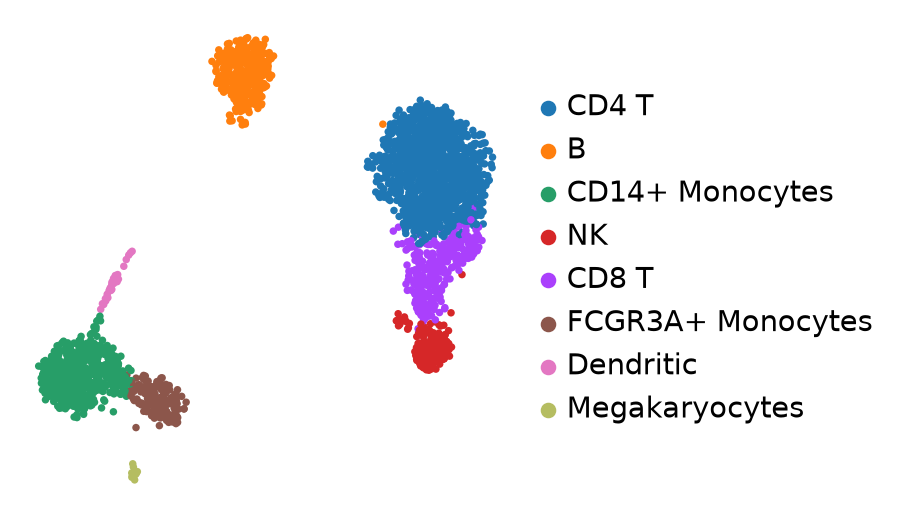

In [49]:
# RENAME LEIDEN CLUSTERS ----------------------------------------------------- #
adata_norm.obs['cell_type'] = adata_norm.obs['leiden']
adata_norm.rename_categories('cell_type',list(new_names.values()))
sc.pl.umap(adata_norm, color="cell_type", title="", frameon=False)